# Training neural networks: challenges and practical choices

CSI 4106 - Fall 2026

Marcel Turcotte  
Version: Oct 31, 2026 13:34

# Preamble

## Message of the Day

<https://youtu.be/0Ge3jKLDJaA>

<a href="https://youtu.be/0Ge3jKLDJaA" class="external"
data-icon="true">The collie and the pug | HackMIT keynote 2026</a>,
Posted on YouTube on 2026-09-24.

> **Note**
>
> Grant Sanderson explores the evolving relationship between technical
> understanding and the act of building in modern software development.
> By comparing the motivations of different approaches, this keynote
> encourages attendees to reflect on their own goals for learning and
> creation during the event.

<a href="https://www.linkedin.com/in/grant-sanderson-950a6239b"
class="external" data-icon="true">Grant Sanderson</a> is the creator of
<a href="https://www.youtube.com/c/3blue1brown" class="external"
data-icon="true">3Blue1Brown</a>, a YouTube channel known for
exceptionally clear, visual explanations of mathematics. His work helped
popularize intuitive, animation-driven math education online.

## Learning objectives

- **Explain** how loss landscapes, activation derivatives, and
  initialization affect optimization.
- **Distinguish** vanishing gradients, exploding gradients, and
  overfitting.
- **Choose** output activations and losses for regression, binary,
  multilabel, and multiclass tasks.
- **Explain** L1, L2, dropout, and early stopping, and interpret their
  effects in code.
- **Compare** `SimplerMLP` with `SimpleMLP` and distinguish inference
  from further learning.
- **Recognize** catastrophic forgetting and explain how replay can
  improve retention.

Lecture 13 computed gradients with backpropagation. This presentation
examines what can still go wrong: optimization can stall or become
unstable, a model can overfit, and further training can damage earlier
capabilities. Output and loss choices specify the prediction problem;
initialization, update rules, and regularization affect how we solve it.

# Loss landscapes and optimization

## We have gradients. What could still go wrong?

Backpropagation was popularized in **1986**. Why did deep learning take
off much later?

- The **loss landscape** describes the objective as a function of the
  parameters.
- A gradient describes the **local** change in that objective.
- Progress also depends on the starting parameters and the learning
  rate.

The influential 1986 paper by Rumelhart, Hinton, and Williams helped
popularize backpropagation for training multilayer neural networks
(Rumelhart et al. 1986). As Lecture 13 noted, earlier work on the method
and reverse-mode automatic differentiation predates that paper. The year
marks an influential demonstration and popularization, rather than the
beginning of all relevant work.

Practical successes appeared well before the modern deep-learning boom.
Networks trained with backpropagation were used for handwriting and
cheque recognition in the 1990s. Broader adoption of large, deep
networks developed later, with speech-recognition advances around 2009
and the 2012 ImageNet image-classification competition serving as
influential milestones (LeCun et al. 2015). Thus, the decades-long
progression concerns the scale and breadth of deep learning’s success;
it does not mean that earlier neural networks were uniformly
ineffective.

Larger labeled datasets and faster computation, particularly graphics
processing units (GPUs), worked alongside **suitable architectures** and
**improved training choices**. AlexNet’s 2012 ImageNet result combined
GPU training, **ReLU activations**, **dropout**, and **additional
training examples generated by transforming existing images**
(Krizhevsky et al. 2012). Backpropagation supplied the gradients within
this larger practical recipe. The activation, initialization,
optimization, and regularization choices in this presentation help
explain why computing those gradients is only part of making learning
work.

Backpropagation answers how the current loss changes when parameters
change. Useful learning also requires an appropriate objective,
effective updates, generalization to unseen examples, and retention when
learning continues. The first difficulty is already visible in a
one-parameter objective: a correct local direction need not lead to a
globally best solution.

The same gradient algorithm can behave differently on different
objectives. A one-dimensional plot lets us inspect a complete toy
landscape. A real neural network usually has many parameters: a drawn
valley or plateau is an illustration of a possible difficulty, not a
complete picture of that network’s objective. A stationary point need
not be a global minimum. High-dimensional objectives can also have
saddle points, where the loss rises in some directions and falls in
others; a one-dimensional plot cannot show all that geometry.

A **local minimum** is at least as good as nearby parameter values; a
**global minimum** is at least as good as every allowed parameter value.
A **stationary point** has zero gradient, where the objective is
differentiable. Such a point can be a minimum, a maximum, or a saddle.
**Convergence** refers to an iterative procedure approaching limiting
parameter values or an objective value; it does not by itself establish
global optimality. Lecture 4 introduced the local/global distinction and
convexity.

Lecture 11 distinguished the existence of useful parameters from finding
them. Backpropagation supplies an efficient gradient computation; it
does not remove that distinction.

## Where will gradient descent take us?

Start at each green point. With a small fixed learning rate, where might
the updates stop?

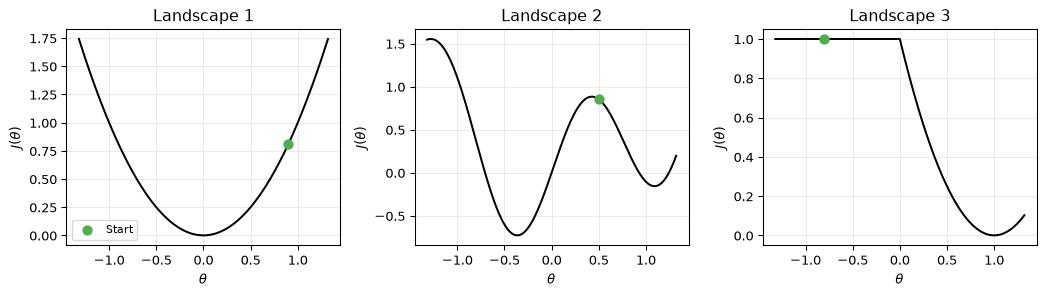

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def gradient_descent_1d(gradient, start, learning_rate, steps, clip_value=None):
    trajectory = [float(start)]
    for _ in range(steps):
        g = float(gradient(trajectory[-1]))
        if not np.isfinite(g):
            break  # The toy objective has no finite derivative here.
        if clip_value is not None:
            g = np.clip(g, -clip_value, clip_value)
        trajectory.append(trajectory[-1] - learning_rate * g)
    return np.asarray(trajectory)

def plot_landscape(objective, trajectory, ax, title, show_trajectory=True):
    left = min(-1.2, trajectory.min())
    right = max(1.2, trajectory.max())
    padding = 0.05 * (right - left)
    theta = np.linspace(left - padding, right + padding, 800)
    ax.plot(theta, objective(theta), color='black', linewidth=1.5)
    if show_trajectory:
        ax.plot(trajectory, objective(trajectory), 'o-', color='#377eb8',
                markersize=3, linewidth=0.8, alpha=0.65)
    ax.scatter(trajectory[0], objective(trajectory[0]), color='#4daf4a',
               s=45, zorder=4, label='Start')
    if show_trajectory:
        ax.scatter(trajectory[-1], objective(trajectory[-1]), color='#d95f02',
                   s=45, zorder=5, label='End')
    ax.set(title=title, xlabel=r'$\theta$', ylabel=r'$J(\theta)$')
    ax.grid(alpha=0.25)
    return theta


fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
overview = [
    ('Convex baseline', lambda t: t**2, lambda t: 2*t, 0.9, 0.1),
    ('Local minima', lambda t: 0.8*np.sin(4*t)+0.5*t**2,
     lambda t: 3.2*np.cos(4*t)+t, 0.5, 0.05),
    ('Suboptimal flat region', lambda t: (np.maximum(0, t)-1)**2,
     lambda t: 2*(t-1) if t > 0 else 0.0, -0.8, 0.1)
]
for index, (ax, (_, objective, gradient, start, rate)) in enumerate(zip(axes, overview)):
    trajectory = gradient_descent_1d(gradient, start, rate, steps=60)
    plot_landscape(objective, trajectory, ax, f'Landscape {index+1}',
                   show_trajectory=False)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

Each plot shows an objective and a starting parameter value, before
revealing the updates. The gradient describes the slope at the current
point; it does not inspect the whole landscape. A horizontal region can
therefore stop the updates even when better parameter values exist
elsewhere. The next figure shows the trajectories using the stated
gradient-descent procedure.

**Are all three objectives differentiable everywhere?** The first two
are. The third, $J(\theta)=(\operatorname{ReLU}(\theta)-1)^2$, has a
kink at $\theta=0$: the slope from the left is 0, whereas the slope from
the right is $-2$. Its derivative is therefore undefined at that point.
The flat region at $\theta<0$ is differentiable, with derivative zero.

Frameworks provide backward rules for common operations at such kinks.
PyTorch’s `torch.relu` uses zero at its kink, so autograd also returns
zero for the third objective at $\theta=0$, matching the rule used in
this example’s code. PyTorch can thus compute backward values for all
three objectives when they are expressed using its tensor operations.
This convention does not make the third objective differentiable
everywhere or help gradient descent escape its flat region. See <a
href="https://docs.pytorch.org/docs/stable/notes/autograd.html#gradients-for-non-differentiable-functions"
class="external" data-icon="true">PyTorch: gradients for
non-differentiable functions</a>.

## Three landscapes, three trajectories

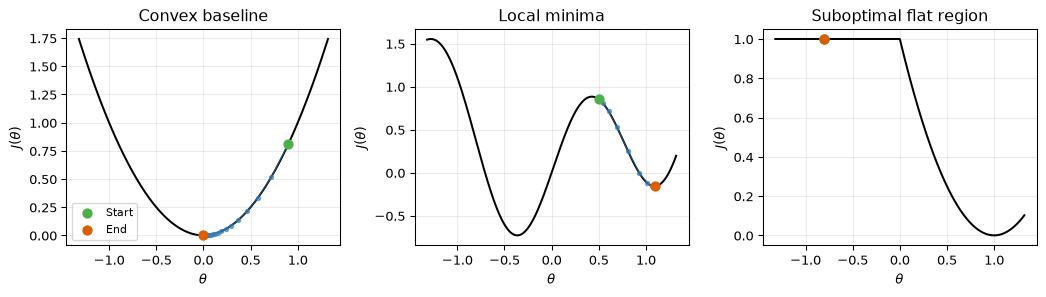

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, (title, objective, gradient, start, rate) in zip(axes, overview):
    trajectory = gradient_descent_1d(gradient, start, rate, steps=60)
    plot_landscape(objective, trajectory, ax, title)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

[Loss landscapes and gradient descent ](loss_functions.qmd): complete
experiments, heatmaps, and clipping comparisons.

The convex baseline approaches its minimum. The nonconvex example
reaches a local minimum selected by its starting point. In the third
example, $J(\theta)=(\operatorname{ReLU}(\theta)-1)^2$: every negative
parameter value has loss 1 and gradient zero, but $\theta=1$ has loss
zero. This is a suboptimal flat region, not an objective that is
constant everywhere.

The companion notebook also includes singular and discontinuous toy
objectives. Those illustrate failures of ordinary differentiability.
They should be distinguished from gradient attenuation or amplification
through a network’s layers.

In those examples, a discontinuity is a jump in the objective’s value.
The square-root cusp has a sharp tip and a derivative whose magnitude
becomes unbounded near that tip. These properties concern the toy
objective itself, whereas the next section studies products of finite
derivatives through a network.

# Gradient propagation and initialization

## What happens along a longer path?

Lecture 13 used one hidden unit. What happens when many backward
transformations are composed?

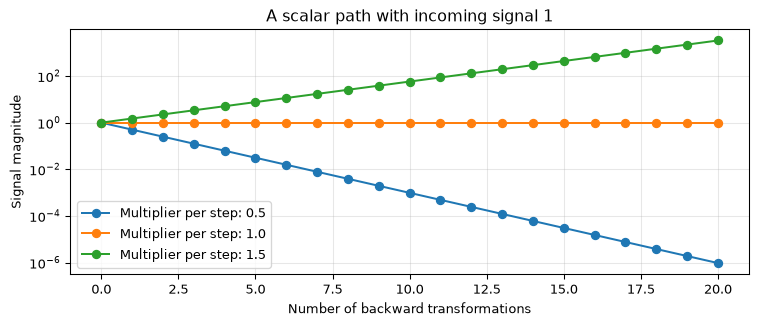

In [3]:
distance = np.arange(21)
fig, ax = plt.subplots(figsize=(8, 3.5))
for factor in (0.5, 1.0, 1.5):
    ax.semilogy(distance, factor**distance, 'o-', label=f'Multiplier per step: {factor}')
ax.set(xlabel='Number of backward transformations', ylabel='Signal magnitude',
       title='A scalar path with incoming signal 1')
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

$\delta_l=w_{l+1}\varphi'(z_l)\,\delta_{l+1}$, where
$w_{l+1}\varphi'(z_l)$ is the **multiplier per step**.

The **multiplier per step**, also called the local factor here, combines
a weight with an activation derivative. Recall Lecture 13’s scalar
notation: $z_l$ is the preactivation of the unit in layer $l$, $w_{l+1}$
is the weight connecting it to the next unit, and the **error signal**
$\delta_l=\partial\ell/\partial z_l$ measures the loss’s sensitivity to
that preactivation. With one unit per layer, backpropagation gives

$$
\delta_l=\underbrace{w_{l+1}\varphi'(z_l)}_{q_l}\,\delta_{l+1}.
$$

The factor $\varphi'(z_l)$ is the activation’s local derivative
evaluated at the cached preactivation. Thus $q_l$ is the multiplier
applied when the signal moves one step towards the input. It is not the
learning rate or an entire parameter gradient. The plot deliberately
uses the **same positive multiplier $q$ at every step**, starting with
signal magnitude 1. After $d$ backward steps the magnitude is $q^d$:
$q=0.5$ halves it at each step, $q=1$ preserves it, and $q=1.5$
increases it by 50% per step. The vertical axis is logarithmic so that
both attenuation and amplification remain visible.

In an actual network the factors depend on the layer and example, can be
negative, and need not be equal. Negative factors can reverse the
signal’s sign; this plot uses positive factors to isolate changes in
magnitude.

The landscapes illustrated a local objective’s geometry. This example
isolates a different mechanism: composing many local derivatives can
change the signal’s scale dramatically, even when every individual
factor is finite.

This is a single-path illustration. A general network also sums
contributions at branches, as in Lecture 13. The sigmoid derivative’s
bound of $0.25$ does not bound all complete parameter gradients because
weights and other paths also contribute.

## Vanishing gradients

- Backpropagation repeatedly multiplies **weights and local activation
  derivatives**.
- Small factors can make early-layer gradients too small for effective
  learning.
- Saturated sigmoid units have derivatives close to zero.

Recall $\sigma'(z)=\sigma(z)(1-\sigma(z))\leq 0.25$.

Lecture 13’s scalar example contained one hidden derivative. A deeper
network introduces more such factors along each path. The sigmoid
derivative approaches zero for large positive or negative
preactivations, so saturated units can strongly attenuate the signal
propagated upstream.

An activation is **saturated** when changing its input produces very
little change in its output, so its local derivative is close to zero.
For a sigmoid, this occurs near either end of its output range.
**Upstream** means towards the inputs along the backward computation;
**downstream** means towards the output and loss.

Weights also enter these products and different paths contribute sums:
the bound of $0.25$ on a sigmoid’s local derivative is not a bound on
every complete parameter gradient. Gradients can shrink or grow
depending on the combined transformations. Both vanishing and exploding
gradients can occur in feed-forward as well as recurrent networks.

For sigmoid output with binary cross-entropy, the output error signal
simplifies to $\hat p-y$. The explicit sigmoid factor cancels there, but
hidden sigmoid units still contribute their activation derivatives. This
is why the simplified output formula does not remove the hidden-layer
problem.

## Exploding gradients

- Repeated transformations can **amplify** backward signals.
- Large gradients can cause **large parameter updates** and unstable
  training.
- Suitable initialization and a sensible learning rate help; **gradient
  clipping** can limit updates.

Exploding gradients do not require an activation with an infinite
derivative. Multiplying a sequence of finite transformations can
suffice. The difficulty can occur in feedforward and recurrent networks.
Large derivatives at a cusp in a scalar objective are a different
mechanism, although clipping can bound an update in either situation.

## Activation functions and their derivatives

Which slopes keep a backward signal useful? Does ReLU solve every
problem?

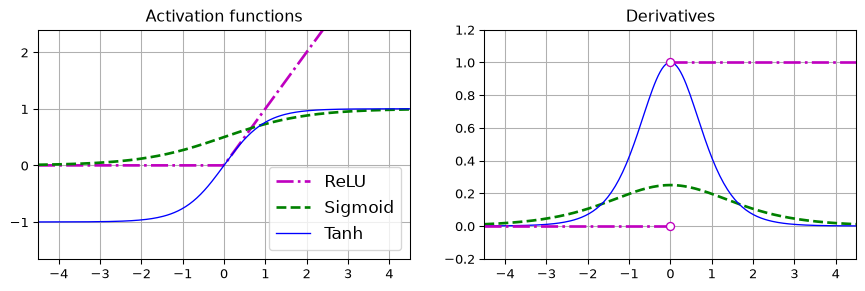

In [4]:
# Attribution: https://github.com/ageron/handson-ml3/blob/main/10_neural_nets_with_keras.ipynb

import numpy as np
import matplotlib.pyplot as plt

from scipy.special import expit as sigmoid

def relu(z):
    return np.maximum(0, z)

def derivative(f, z, eps=0.000001):
    return (f(z + eps) - f(z - eps))/(2 * eps)

max_z = 4.5
z = np.linspace(-max_z, max_z, 200)

plt.figure(figsize=(11, 3.1))

plt.subplot(121)
plt.plot(z, relu(z), "m-.", linewidth=2, label="ReLU")
plt.plot(z, sigmoid(z), "g--", linewidth=2, label="Sigmoid")
plt.plot(z, np.tanh(z), "b-", linewidth=1, label="Tanh")
plt.grid(True)
plt.title("Activation functions")
plt.axis([-max_z, max_z, -1.65, 2.4])
plt.gca().set_yticks([-1, 0, 1, 2])
plt.legend(loc="lower right", fontsize=13)

plt.subplot(122)
plt.plot(z, derivative(sigmoid, z), "g--", linewidth=2, label="Sigmoid")
plt.plot(z, derivative(np.tanh, z), "b-", linewidth=1, label="Tanh")
plt.plot([-max_z, 0], [0, 0], "m-.", linewidth=2)
plt.plot([0, max_z], [1, 1], "m-.", linewidth=2)
plt.plot([0, 0], [0, 1], "mo", markersize=6, markerfacecolor="white")
plt.grid(True)
plt.title("Derivatives")
plt.axis([-max_z, max_z, -0.2, 1.2])

plt.show()

Géron (2022) – <a
href="https://github.com/ageron/handson-ml3/blob/main/10_neural_nets_with_keras.ipynb"
class="external" data-icon="true">10_neural_nets_with_keras.ipynb</a>

Activation choice affects gradient propagation and therefore training.
You need to interpret these slopes and how the chain rule uses them,
rather than manually derive every expression.

Sigmoid’s maximum derivative is $0.25$, and its derivative approaches
zero at both extremes. The $\tanh$ derivative has maximum one at zero
and also approaches zero in its saturated tails.

For ReLU, the derivative is zero for negative preactivations and one for
positive preactivations. At zero the ordinary derivative is undefined;
implementations choose a value by convention, commonly zero. The open
circles mark the missing ordinary derivative. The activation itself can
take any nonnegative value: it is the derivative, away from zero, that
takes values zero or one.

**Sparsity** means that many entries are exactly zero. ReLU produces
sparse activations because it outputs zero for nonpositive inputs; this
describes the activations for particular examples, rather than saying
that the weights are zero. A zero activation for one example is normal.
A unit that remains in this region across the relevant training inputs
receives no data-loss gradient through its activation and may remain
inactive: the dying ReLU problem. This is persistent inactivity, not
simply one zero output. Changes in upstream representations can
sometimes reactivate a unit, so inactivity is not invariably
irreversible. See
<a href="https://arxiv.org/abs/1903.06733" class="external"
data-icon="true">Lu et al. (2019)</a>.

ReLU’s positive-side derivative avoids one source of attenuation, but
does not make the entire gradient equal to one. Incoming activations,
downstream weights, other activation derivatives, and path sums still
matter. Leaky ReLU retains a small negative-side slope, reducing this
particular risk.

## Keeping a gradient on the negative side

What if a ReLU unit stays inactive across the training examples?

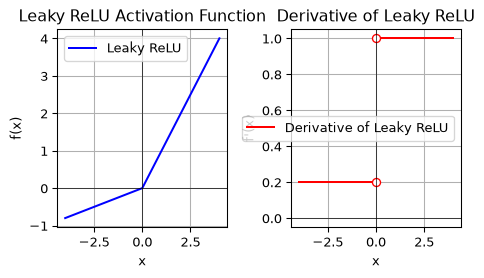

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Define the Leaky ReLU function
def leaky_relu(x, alpha=0.2):
    return np.where(x > 0, x, alpha * x)

# Define the derivative of the Leaky ReLU function
def leaky_relu_derivative(x, alpha=0.2):
    return np.where(x > 0, 1, alpha)

# Generate a range of input values
x_values = np.linspace(-4, 4, 400)

# Compute the Leaky ReLU and its derivative
leaky_relu_values = leaky_relu(x_values)
leaky_relu_derivative_values = leaky_relu_derivative(x_values)

# Create the plot
plt.figure(figsize=(5, 3))

# Plot the Leaky ReLU
plt.subplot(1, 2, 1)
plt.plot(x_values, leaky_relu_values, label='Leaky ReLU', color='blue')
plt.title('Leaky ReLU Activation Function')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid(True)
plt.axhline(0, color='black',linewidth=0.5)
plt.axvline(0, color='black',linewidth=0.5)
plt.legend()

# Plot the derivative of the Leaky ReLU
plt.subplot(1, 2, 2)
plt.plot([-4, 0], [0.2, 0.2], label='Derivative of Leaky ReLU', color='red')
plt.plot([0, 4], [1, 1], color='red')
plt.plot([0, 0], [0.2, 1], 'o', color='red', markerfacecolor='white')
plt.title('Derivative of Leaky ReLU')
plt.xlabel('x')
plt.ylabel("f'(x)")
plt.grid(True)
plt.axhline(0, color='black',linewidth=0.5)
plt.axvline(0, color='black',linewidth=0.5)
plt.legend()

# Show the plots
plt.tight_layout()
plt.show()

The Leaky ReLU, a variant of the standard ReLU activation function,
effectively mitigates the issue of *dying ReLU nodes*. For negative
input values, it introduces a linear component with a slope governed by
the parameter `negative_slope`.

Leaky ReLU retains a nonzero negative-side derivative, reducing the risk
of persistent inactivity through a zero activation gradient. At zero its
ordinary derivative is undefined when the two slopes differ; an
implementation chooses a convention. The open circles distinguish this
mathematical point from the code’s chosen value.

``` python
import keras

leaky_relu = keras.layers.LeakyReLU(negative_slope=0.2)
dense = keras.layers.Dense(50, activation=leaky_relu, kernel_initializer="he_normal")
```

See the
<a href="https://keras.io/api/layers/activations/" class="external"
data-icon="true">Keras activation functions</a> for other choices.

## Why not start every weight at the same value?

Randomly initialized **weights** break symmetry between units.
**Biases** can start at zero.

Units with identical initial parameters and identical roles can receive
identical gradients. Random weight initialization gives them different
starting computations. Choosing an initialization scale appropriate to
the activation helps signal propagation; it does not guarantee
convergence or optimal performance.

## Glorot and Bengio

Random weights break symmetry. Does their scale matter?

Activations

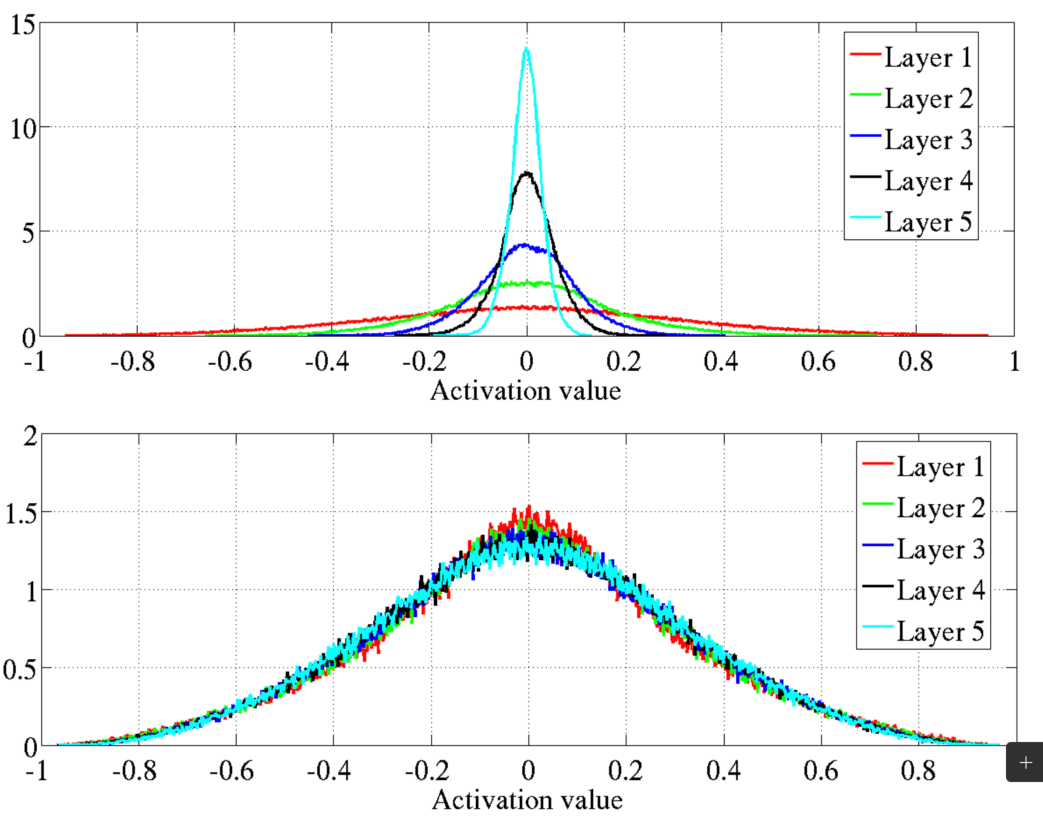

Backward signals

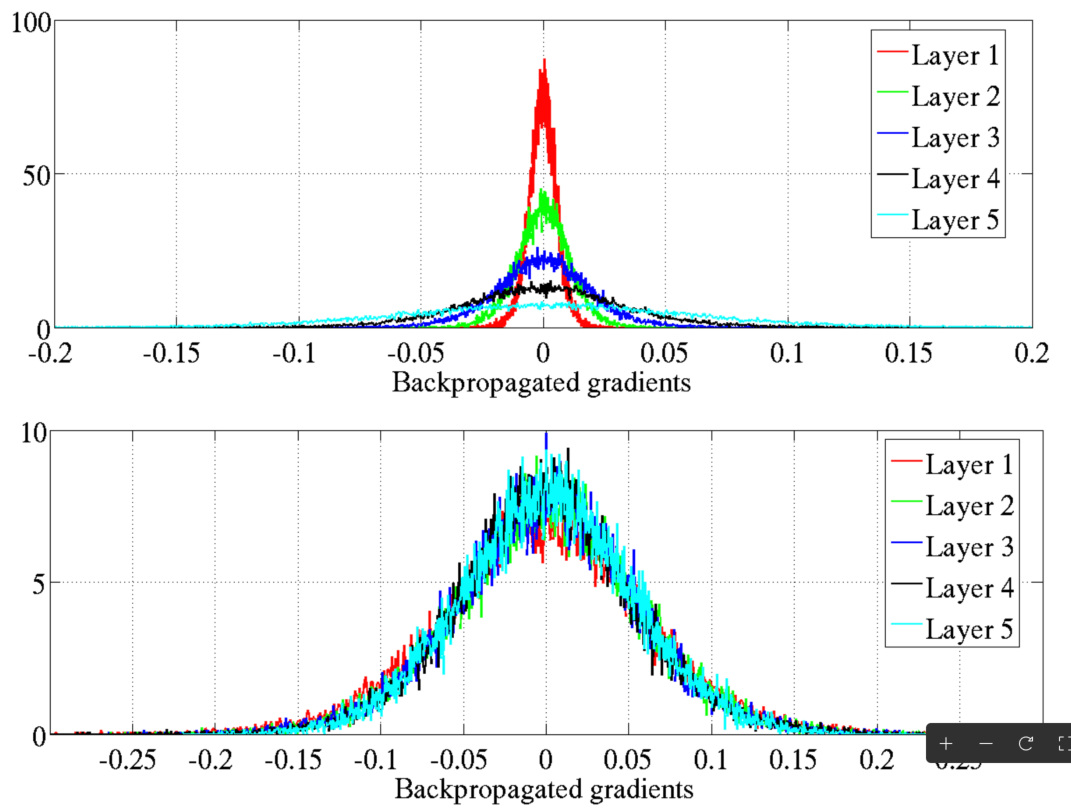

Glorot and Bengio (2010), page 254.

These figures compare standard initialization (top) with the normalized
initialization proposed by Glorot and Bengio (bottom), for a network
with $\tanh$ units (Glorot and Bengio 2010, 254). Figure 6 shows
activation histograms; Figure 7 shows back-propagated-gradient
histograms. With the standard initialization, activations become more
concentrated near zero in later layers, while back-propagated gradients
are more concentrated near zero closer to the input. Normalized
initialization reduces the discrepancy across layers in these
experiments.

These are distributions for the reported setup, not a universal rule
that vanishing gradients always imply small forward activations. A
saturated sigmoid can have an activation near one and a derivative near
zero. The paper also distinguishes back-propagated signals from weight
gradients; their layerwise distributions need not behave identically.

The Xavier/Glorot normal initializer balances input and output layer
widths using
$\operatorname{Var}(W)=2/(n_{\mathrm{in}}+n_{\mathrm{out}})$. It is the
scaled random initialization already used by `SimplerMLP`. Here
$n_{\mathrm{in}}$ and $n_{\mathrm{out}}$ count the inputs and outputs of
the layer. The variance refers to each sampled weight entry; the normal
distribution’s standard deviation is the square root of that variance.

## He initialization

For ReLU hidden layers, He normal initialization uses

$$
\operatorname{Var}(W)=\frac{2}{n_{\mathrm{in}}}.
$$

``` python
def he_init(rng, fan_in, fan_out):
    std = np.sqrt(2.0 / fan_in)
    return rng.normal(0.0, std, size=(fan_in, fan_out))
```

Also called Kaiming initialization.

The scaling accounts for the rectifier’s effect on signal variance.
`SimpleMLP` will use He initialization for ReLU hidden layers and
Xavier/Glorot initialization for sigmoid layers, including the output
layer. These are initialization rules, not guarantees about the entire
training trajectory. See
<a href="https://arxiv.org/abs/1502.01852" class="external"
data-icon="true">He et al. (2015)</a> for the rectifier analysis.

## Which choices help gradients propagate?

- **Alternative activation functions**: Rectified Linear Unit (**ReLU**)
  and its variants (e.g., **Leaky ReLU**, **Parametric ReLU**, and
  **Exponential Linear Unit**).

- **Weight Initialization**: Xavier (Glorot) or He initialization.

Activation functions and initialization influence the propagation of
signals in both directions. ReLU avoids saturation for positive
preactivations, but its zero derivative on the negative side creates the
persistent-inactivity risk illustrated earlier. Activation choice and
initialization scale work together; neither guarantees stable gradients
in an arbitrarily deep network. **Normalization layers** and **residual
connections** provide other approaches beyond this worked
implementation. Even with suitable initial conditions, unusually large
updates can still occur, motivating control of the update itself.

## Gradient clipping

How could we limit an excessively large gradient-descent step while
preserving its direction?

For a gradient vector $g$ and threshold $c>0$:

$$
\widetilde g =
\begin{cases}
g, & \|g\|_2\leq c,\\
c\,g/\|g\|_2, & \|g\|_2>c.
\end{cases}
$$

The update uses $\widetilde g$. Its norm is bounded by $c$.

``` python
optimizer = keras.optimizers.SGD(learning_rate=0.01, global_clipnorm=1.0)
```

Global-norm clipping rescales the concatenated parameter gradient when
necessary while preserving its direction. This differs from clipping
each coordinate separately; the two coincide for a scalar gradient. With
learning rate $\alpha$, the corresponding gradient-descent step has norm
at most $\alpha c$.

Here $g$ is a vector containing the derivatives with respect to all
parameters, laid out as one list; one coordinate corresponds to one
weight or bias. Its **L2 or Euclidean norm** is
$\|g\|_2=\sqrt{\sum_j g_j^2}$, the vector’s length. The threshold $c$
bounds this combined length, rather than bounding each entry separately.
The general norm definitions appear later in the regularization section.

Clipping does not repair vanishing gradients or guarantee convergence.
The companion notebook compares clipped and unclipped updates with
identical settings and shows a cusp example where fixed-size updates
keep oscillating. Initialization, activation choice, clipping, and the
learning-rate schedule address different aspects of training.

## Learning-rate decay

Could smaller steps help later in training? What if we reduce them too
soon?

At epoch $t=1,2,\ldots$, with decay factor $0<\gamma<1$:

$$
\alpha_t=\alpha_1\gamma^{t-1}.
$$

``` python
if self.lr_decay is not None:
    self.lr = self.base_lr * self.lr_decay ** (ep - 1)
```

The first epoch uses the initial learning rate; subsequent epochs use
progressively smaller steps. With `lr_decay=None`, the learning rate
stays constant. Decay changes the optimizer’s step size, not the
derivative formulas or the objective. It is different from L2
regularization and from weight decay. Reducing the learning rate too
quickly can prevent useful progress; it does not repair vanishing
gradients.

An **epoch** here is one pass through the training examples, possibly
divided into mini-batches. **Weight decay** means directly shrinking
weights during parameter updates.

# Output layers

## Should the output activation also change?

We replaced a hidden sigmoid with ReLU. Should we do the same at the
output?

For **regression**, the output must match the target’s dimensions and
range:

- **\# of output neurons**:
  - 1 per dimension
- **Output layer activation function**:
  - Linear for unconstrained targets; ReLU/softplus for nonnegative
    targets; sigmoid/tanh for bounded targets.
- **Loss function**:
  - <a
    href="https://www.tensorflow.org/api_docs/python/tf/keras/losses/MeanSquaredError"
    class="external" data-icon="true">MeanSquaredError</a>

In an
<a href="https://keras.io/guides/keras_cv/object_detection_keras_cv/"
class="external" data-icon="true">object detection problem</a>,
determining the **bounding box** exemplifies a regression task where the
output is multidimensional.

The preceding section changed hidden activations to influence gradient
propagation. The output has an additional obligation: its values must
represent the required predictions. Replacing the output sigmoid with
ReLU changes the model’s possible outputs and their interpretation,
rather than simply improving an internal derivative.

In a feed-forward network, activation functions in the hidden layers are
chosen mainly for their impact on performance and convergence, while the
activation function in the output layer is selected according to the
requirements of the task.

- **Hidden layers:**

  The activation function (e.g., sigmoid, tanh, ReLU) mainly affects
  *training dynamics* — such as gradient flow, nonlinearity strength,
  and convergence rate. The choice is typically empirical, guided by
  performance, numerical stability, and optimization behavior.

- **Output layer:**

  The activation function is determined by the **nature of the
  prediction task**:

  - *Regression*: linear, ReLU, or softplus (depending on range
    constraints)
  - *Binary classification*: sigmoid
  - *Multi-class classification*: softmax
  - *Multi-label classification*: sigmoid (per output unit)

**Softplus** is the smooth function
$\operatorname{softplus}(z)=\log(1+e^z)$. It produces strictly positive
values for finite inputs and approaches zero for very negative inputs,
making it one option for positive regression outputs. ReLU can also
represent an exact zero. **Linear** output activation means the identity
function: the output is the affine score itself. See the
<a href="https://keras.io/api/layers/activations/" class="external"
data-icon="true">Keras activation definitions</a>.

Examples of **multi-output regression problems** (2–4 outputs) include:

- **2 outputs:**

  - Predicting both the **latitude and longitude** of a location from an
    image.
  - Estimating the **width and height** of a bounding box in object
    detection.
  - Forecasting **temperature and humidity** simultaneously.

- **3 outputs:**

  - Predicting the **x, y, z coordinates** of a point in space (e.g.,
    hand-joint localization).
  - Estimating **RGB color values** from spectral measurements.

- **4 outputs:**

  - Predicting **bounding box coordinates** —
    $(x_{min}, y_{min}, x_{max}, y_{max})$ — in object detection.

## Can these probabilities describe one exclusive choice?

Separate sigmoids give $[0.8,\;0.7,\;0.1]$. Could several labels apply?
Could exactly one class apply?

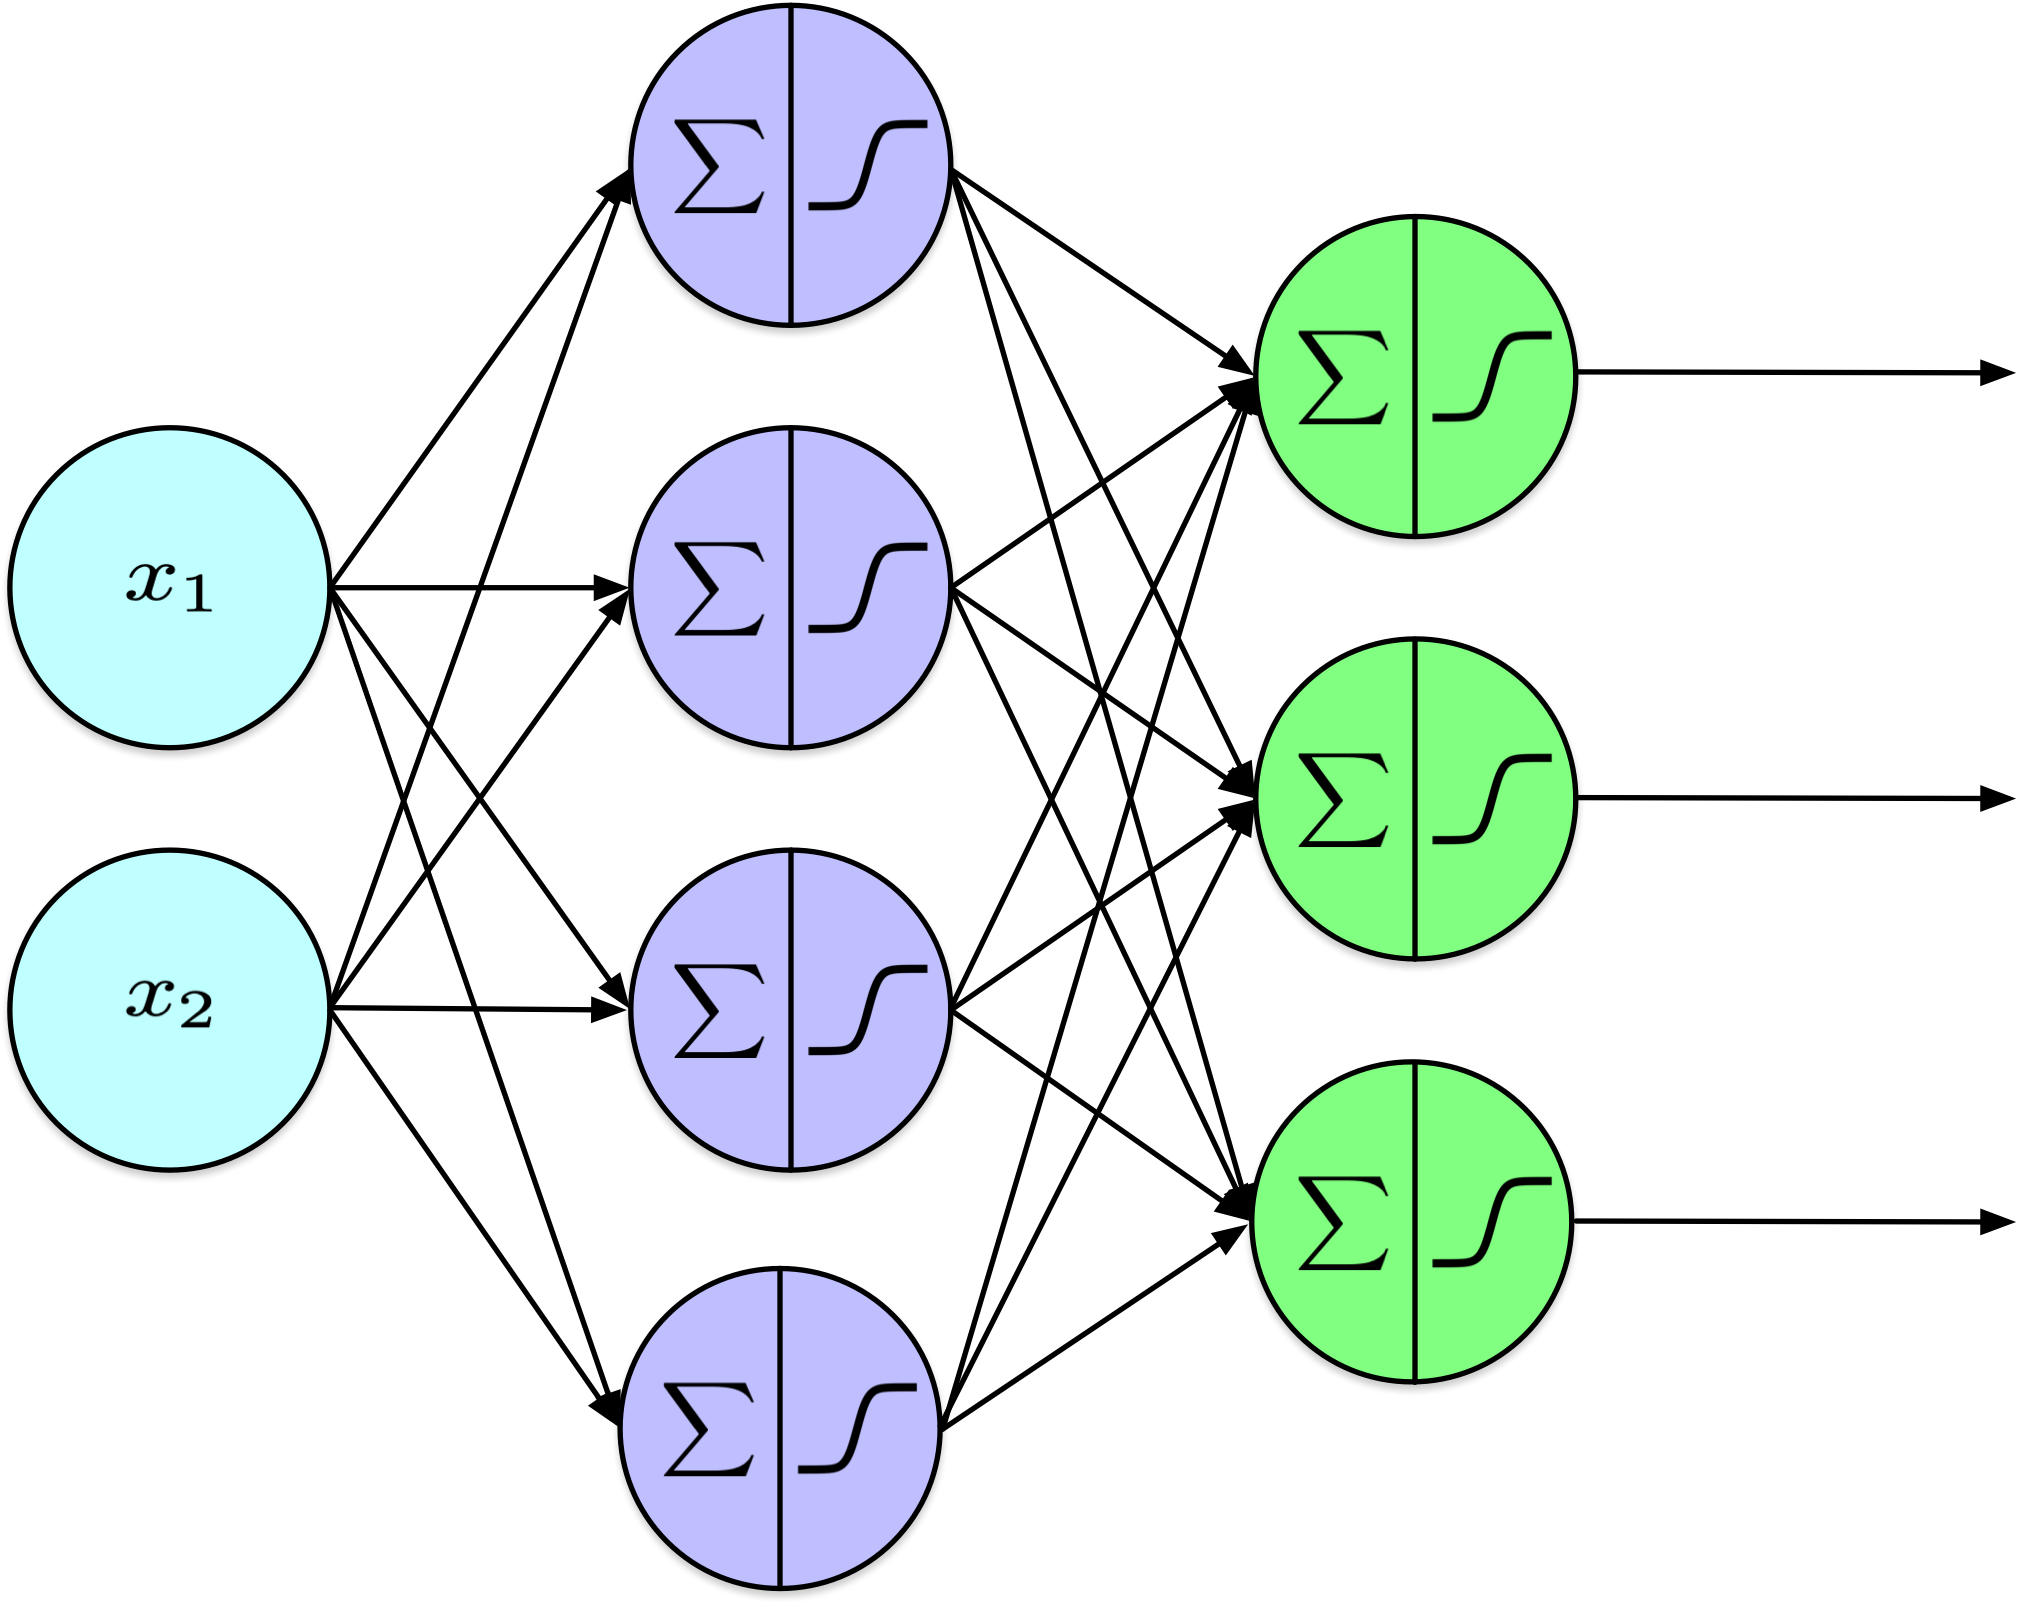

Independent sigmoid outputs suit multi-label predictions; their
probabilities need not sum to one.

The proposed values sum to 1.6. They can be probabilities of separate
labels that may coexist, such as several objects present in one image.
They cannot directly form a distribution over an exhaustive set of
mutually exclusive classes, whose probabilities must sum to one. This
difference concerns the meaning of the outputs, not simply the number of
output units.

## One shared output distribution

What properties should the output have when exactly one of $K$ classes
is correct?

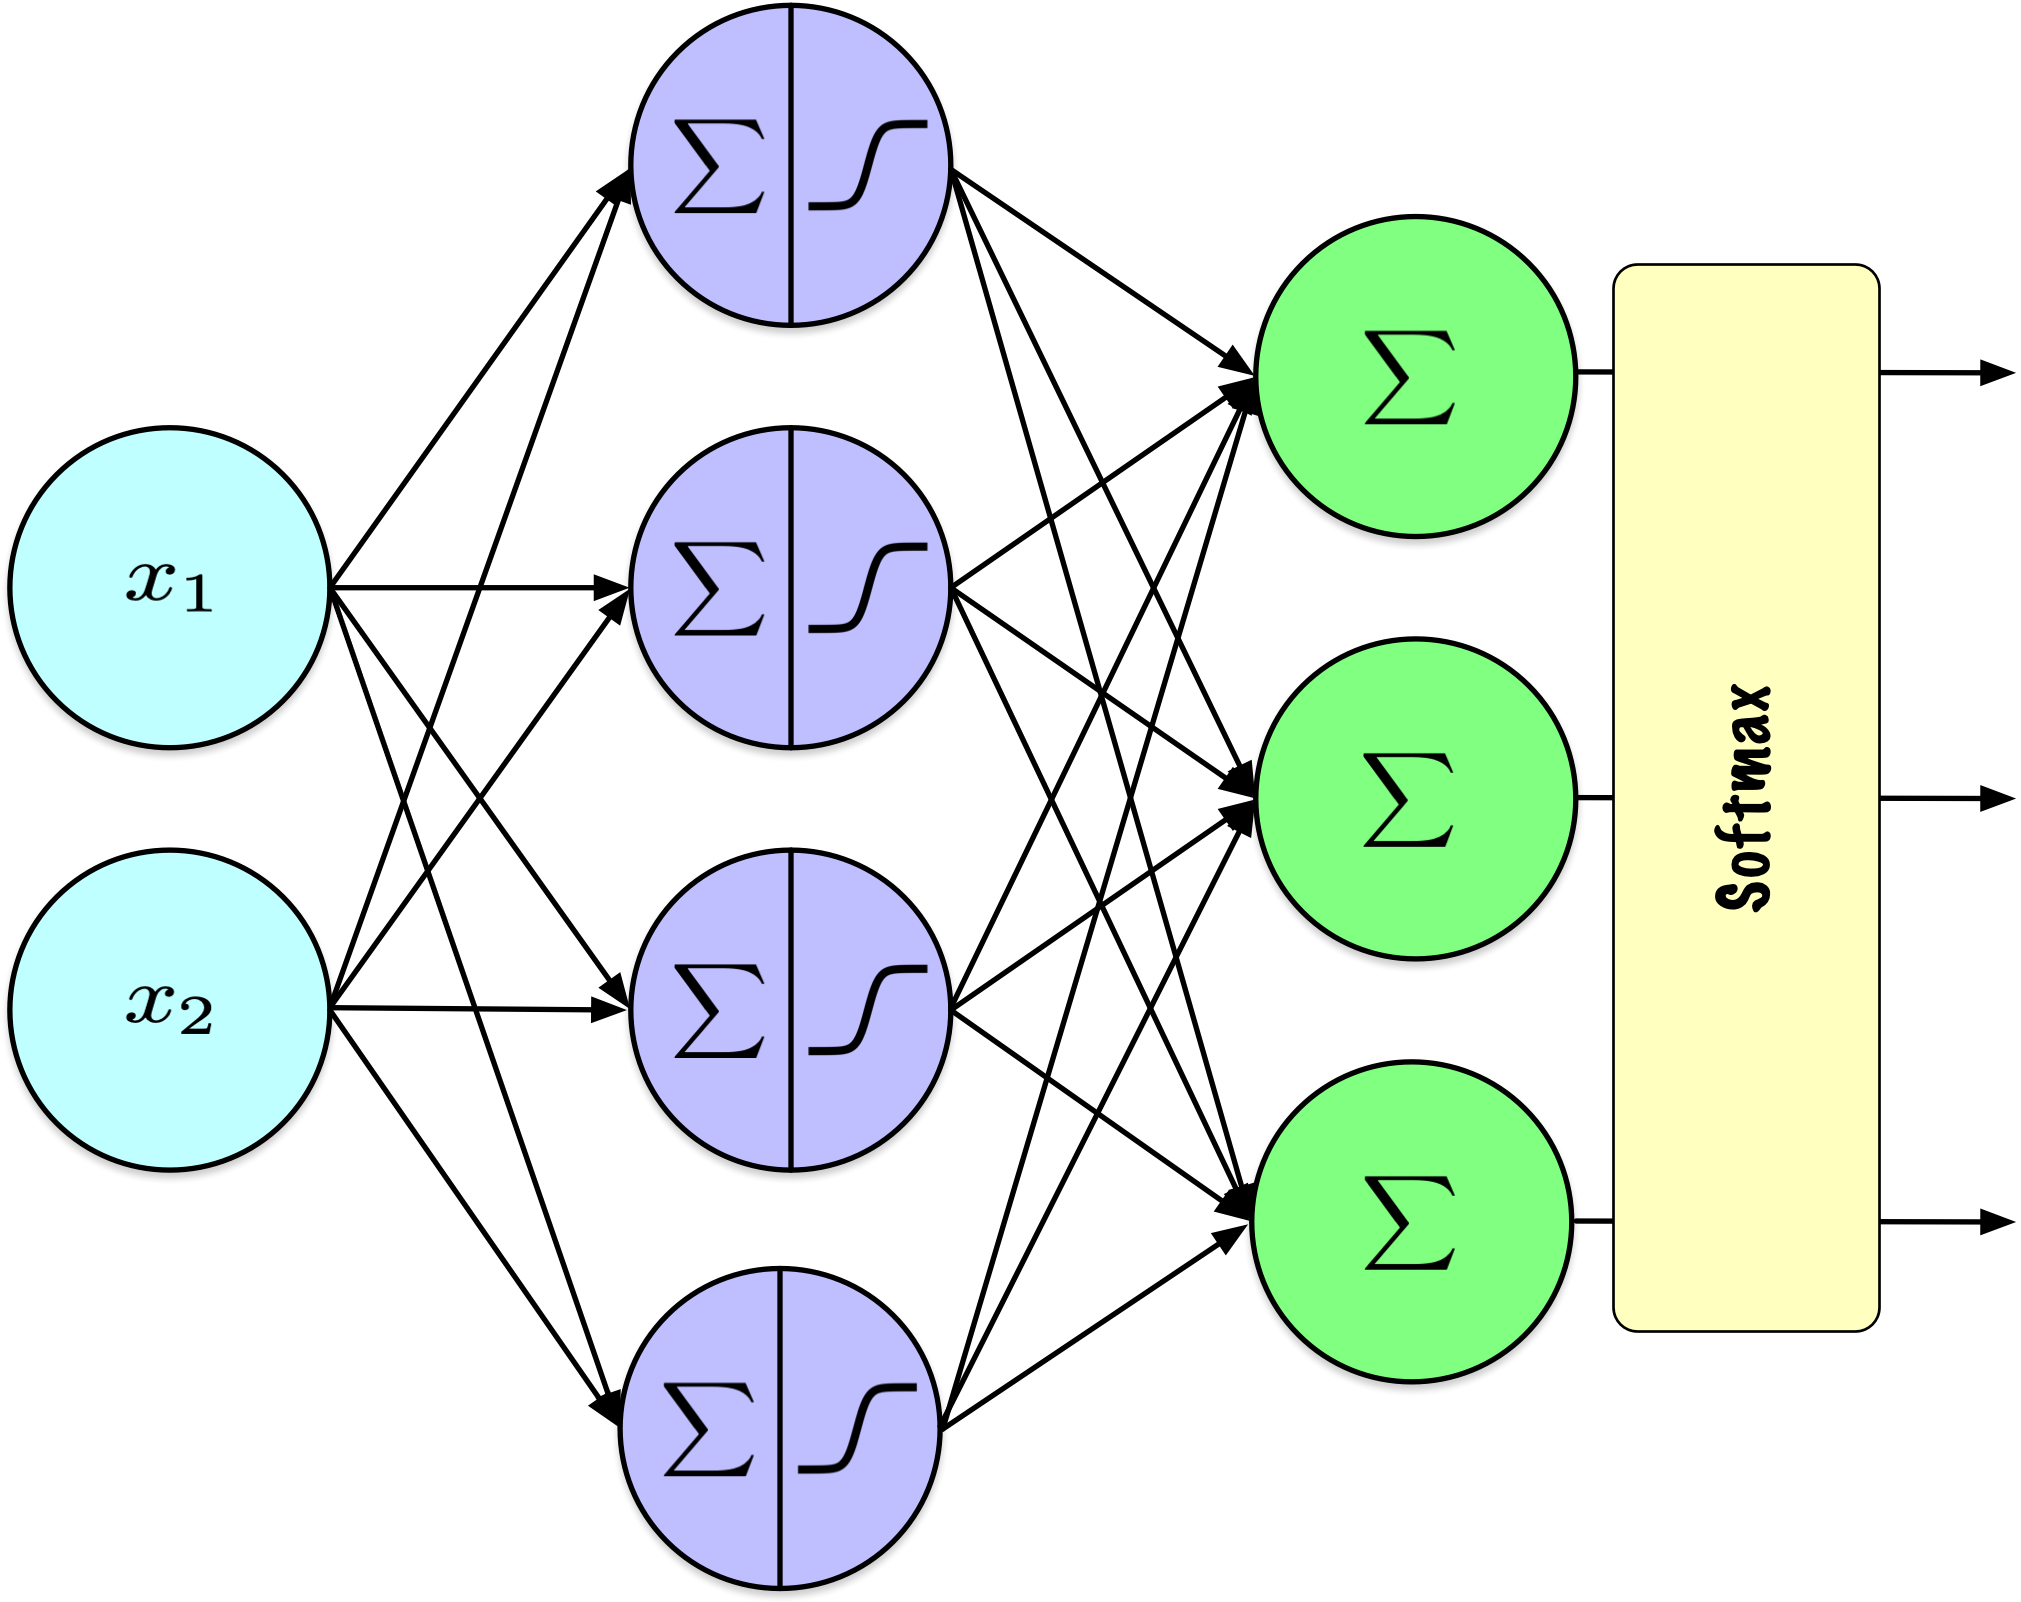

**Softmax** ensures that all activation outputs fall between 0 and 1 and
collectively sum to 1.

An output **logit** is an unrestricted real-valued score before the
final sigmoid or softmax converts scores into probabilities. In the
diagram these are the output layer’s preactivations. The diagram applies
softmax to the whole output vector: each probability depends on every
output logit through the shared denominator. Sigmoid outputs for a
multilabel task are instead computed elementwise and need not sum to
one.

The required properties motivate the construction: outputs should be
nonnegative, sum to one, and support gradient computation. Softmax is a
standard differentiable way to obtain such a distribution from
unrestricted scores; these requirements alone do not uniquely determine
its exponential formula.

The $\operatorname{argmax}$ function is not suitable for optimization
via gradient-based methods because it is piecewise constant, with zero
derivatives away from ties and undefined derivatives at relevant
boundaries. In contrast, the softmax function offers both a
probabilistic interpretation and a computable derivative, making it more
effective for such applications.

The $\operatorname{argmax}$ function can be applied *a posteriori* to
trained networks for class prediction.

As in Lecture 11, **argmax** returns the index of a largest entry. It
selects a class, whereas softmax returns the complete vector of class
probabilities.

## From scores to a probability distribution

The **softmax** function is an **activation function** used in
**multi-class classification problems** to convert a vector of raw
scores into **probabilities that sum to 1**.

Given $K$ output logits $\mathbf{z} = [z_1, z_2, \ldots, z_K]$:

$$
\hat p_k=\operatorname{softmax}(\mathbf{z})_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}
$$

Here $\hat p_k$ is the predicted probability of class $k$.

The output logits are real-valued scores. Exponentiation makes their
transformed values positive, and normalization makes the probabilities
sum to one. Equal logits give probability $1/K$ to every class. Adding
the same constant to every logit leaves the probabilities unchanged.

Softmax preserves ordering: the largest logit and largest probability
identify the same class. Probability ratios satisfy
$\hat p_i/\hat p_j=e^{z_i-z_j}$. These are relative scores, not a
guarantee that the prediction is correct. Zero probabilities are
permitted in probability distributions generally; positivity is a
property of mathematical softmax at finite logits.

## What do differences between scores imply?

Which class wins? How does the gap between scores affect its
probability?

|    $z_1$ |    $z_2$ |    $z_3$ | $\hat p_1$ | $\hat p_2$ | $\hat p_3$ | $\sum$ |
|---------:|---------:|---------:|-----------:|-----------:|-----------:|-------:|
| **1.47** |    -0.39 |     0.22 |   **0.69** |       0.11 |       0.20 |   1.00 |
|     5.00 | **6.00** |     4.00 |       0.24 |   **0.67** |       0.09 |   1.00 |
|     0.90 |     0.80 | **1.10** |       0.32 |       0.29 |   **0.39** |   1.00 |
|    -2.00 | **2.00** |    -3.00 |       0.02 |   **0.98** |       0.01 |   1.00 |

Softmax values for a vector of length 3.

1.  **Maintains Relative Order**: The softmax function preserves the
    relative order of the input values. If one input is greater than
    another, its corresponding output will also be greater.

2.  **Interpreted as probabilities**: Each value is in the range 0 to 1.
    The output values from the softmax function are normalized to sum to
    one, which allows them to be interpreted as probabilities.

3.  **Relative Differences**: When the differences among logits are
    small, probabilities remain close to uniform. When all logits are
    identical, every output probability is $\frac{1}{K}$.

4.  **Rounding**: Displayed probabilities can sum to 1.01 in the last
    row because each entry was rounded separately. The unrounded
    probabilities sum to one. Numerical stability requires the shifted
    computation discussed next.

These properties make the softmax function particularly useful for
multi-class classification tasks in machine learning.

**Computing softmax safely**

What happens if the logits are $1000$, $1001$, and $999$?

Subtracting the largest logit leaves the probabilities unchanged:

$$
\hat p_k=\frac{e^{z_k-m}}{\sum_j e^{z_j-m}},\qquad m=\max_j z_j.
$$

Directly exponentiating very large positive scores can overflow.
Subtracting the maximum prevents that overflow. Very small probabilities
can still underflow, so production libraries usually combine the loss
with the logits using stable log-sum-exp computations. See <a
href="https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.softmax.html"
class="external" data-icon="true">SciPy softmax</a>.

**Overflow** occurs when a computed magnitude exceeds the range of the
floating-point representation; **underflow** can round a sufficiently
small nonzero result to zero. A **numerically stable** computation
avoids unnecessary losses of accuracy or range caused by intermediate
operations.

**Log-sum-exp** names the function $\log\left(\sum_j e^{z_j}\right)$. It
can be evaluated in the shifted form

$$
\log\left(\sum_j e^{z_j}\right)
=m+\log\left(\sum_j e^{z_j-m}\right),\qquad m=\max_j z_j.
$$

A combined cross-entropy implementation can use this expression rather
than taking the logarithm of a probability that has already underflowed
to zero. See <a
href="https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.logsumexp.html"
class="external" data-icon="true">SciPy logsumexp</a>.

When the final Dense layer returns logits, use a cross-entropy loss
configured with `from_logits=True`. When it returns softmax
probabilities, use `from_logits=False`. Applying softmax first and then
declaring the values to be logits changes the objective.

The appendix provides an [executable
example](#stable-softmax-computation) of the shifted softmax
calculation.

## Limitations

What limitations can you think of?

Our Fashion-MNIST classifier receives an image of a handwritten **7**.
What will it predict?

Softmax distributes all probability among the **known classes**. There
is no built-in **“none of these”** output.

The Fashion-MNIST classifier has outputs for clothing classes, not
handwritten digits. When given a handwritten 7, it still produces
probabilities for those clothing classes. Applying argmax selects one of
them, even though none is the correct description of the input. Softmax
constructs a probability vector; argmax makes the class decision.

An example from a class absent from the training task is an
**out-of-distribution** input. Such an input can receive a high
predicted probability for a known class. The probabilities sum to one
because of the output transformation, not because the model has
established that one of its known classes applies.

Using softmax followed by argmax therefore gives no automatic “I don’t
know” response. An application can add a rule that rejects some inputs
instead of returning a class. For example, the largest predicted
probability can be compared with a threshold. This can help, but
unfamiliar inputs can still receive high probabilities and escape
rejection. See
<a href="https://arxiv.org/abs/1610.02136" class="external"
data-icon="true">Hendrycks and Gimpel, <em>A Baseline for Detecting
Misclassified and Out-of-Distribution Examples in Neural
Networks</em></a>.

## Can we trust the probabilities?

Among many predictions made with approximately **90% confidence**, what
proportion should be correct?

Approximately **90%**, if the model is **calibrated**.

Probabilities summing to one do not guarantee calibration.

Here **confidence** means the largest predicted class probability,
associated with the class selected by argmax. **Probability
calibration** concerns agreement between predicted probabilities and
observed frequencies. Among many examples for which the selected class
receives approximately 0.9 probability, a calibrated classifier should
be correct approximately 90% of the time. The same agreement should hold
at other confidence levels. This is a statement about groups of
predictions, not a guarantee for an individual example.

Accuracy measures how often the selected class is correct. Calibration
asks whether the reported confidence agrees with that observed
correctness. A classifier can have good accuracy while being
overconfident. Calibration must be assessed on held-out data
representative of the intended use; normalization by softmax alone does
not establish it. See
<a href="https://proceedings.mlr.press/v70/guo17a.html" class="external"
data-icon="true">Guo et al., <em>On Calibration of Modern Neural
Networks</em></a>.

Calibration and recognizing unfamiliar classes are related but distinct
concerns. Good calibration on familiar data does not guarantee that
inputs from previously unseen classes will be detected or rejected.

For further reading, **evidential deep learning** explores learning how
much evidence supports a classification alongside the class
probabilities. See <a
href="https://papers.nips.cc/paper_files/paper/2018/hash/a981f2b708044d6fb4a71a1463242520-Abstract.html"
class="external" data-icon="true">Sensoy, Kaplan, and Kandemir,
<em>Evidential Deep Learning to Quantify Classification
Uncertainty</em></a>. Its uncertainty estimates require evaluation;
subsequent research has identified limitations in existing methods. See
<a
href="https://papers.nips.cc/paper_files/paper/2024/hash/c3177be226ee12e34d6ba3b5e6fe6a5b-Abstract-Conference.html"
class="external" data-icon="true">Shen et al., <em>Are Uncertainty
Quantification Capabilities of Evidential Deep Learning a
Mirage?</em></a>.

## Same predicted class, same loss?

The true class is Setosa. Both predictions select it:

- $[0.25,\;\mathbf{0.51},\;0.24]$
- $[0.005,\;\mathbf{0.99},\;0.005]$

**Cross-entropy** rewards probability assigned to the true class:

$$
\ell = -\sum_{k=1}^{K} y_k \log(\hat p_k)
$$

One-hot target: $y$. Predicted class probabilities: $\hat p_k$.

Both vectors have their largest component in the Setosa position.
Accuracy therefore treats these two predictions equally, whereas a
probability-based training objective can distinguish them. Cross-entropy
gives losses $-\log(0.51)\approx0.6733$ and $-\log(0.99)\approx0.0101$.
The lower loss rewards more probability on the true class. This recalls
Lecture 12’s use of probabilities from `forward` rather than thresholded
labels from `predict` when computing BCE.

- The target vector $y$ is expressed as a one-hot encoded vector of
  length $K$, where the element corresponding to the true class is set
  to 1, and all other elements are 0.

- Consequently, in the summation over classes, only the term associated
  with the true class contributes a non-zero value.

- Therefore, the cross-entropy loss for a single example is given by
  $-\log(\hat p_k)$, where $\hat p_k$ is the predicted probability for
  the true class.

- The predicted probability $\hat p_k$ is derived from the softmax
  function applied in the output layer of the neural network.

## Cross-entropy: a worked example

- **Classification Problem**: 3 classes
  - Versicolour, Setosa, Virginica.
- **One-Hot Encoding**:
  - Setosa = $[0, 1, 0]$.
- **Softmax Outputs & Loss**:
  - $[0.22,\mathbf{0.7}, 0.08]$: Loss = $-\log(0.7) = 0.3567$.
  - $[0.7, \mathbf{0.22}, 0.08]$: Loss = $-\log(0.22) = 1.5141$.
  - $[0.7, \mathbf{0.08}, 0.22]$: Loss = $-\log(0.08) = 2.5257$.

Among the softmax outputs, cross-entropy evaluates only the component
corresponding to $k=2$ (Setosa), as the other entries in the one-hot
encoded vector are zero. Here mathematical class indices run from 1 to
3. This relevant element is highlighted in bold. A higher probability
for the true class produces a smaller loss; the three examples give
losses of 0.3567, 1.5141, and 2.5257.

## How strongly should confident mistakes be penalized?

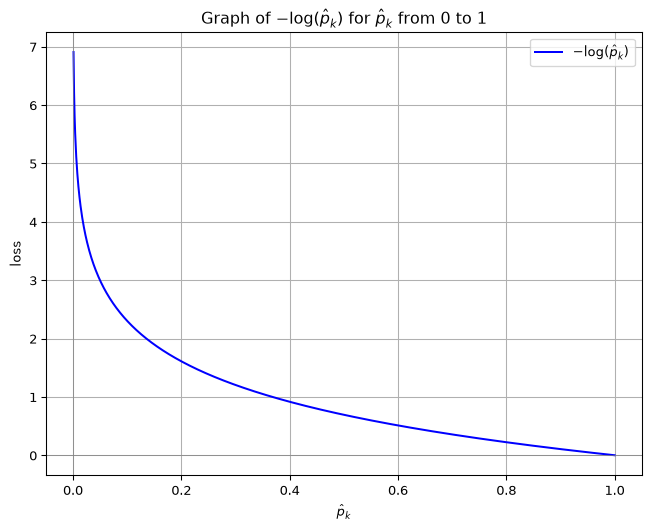

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Generate an array of p values from just above 0 to 1
p_values = np.linspace(0.001, 1, 1000)

# Compute the natural logarithm of each p value
ln_p_values = - np.log(p_values)

# Plot the graph
plt.figure(figsize=(8, 6))
plt.plot(p_values, ln_p_values, label=r'$-\log(\hat p_k)$', color='b')

# Add labels and title
plt.xlabel(r'$\hat p_k$')
plt.ylabel(r'loss')
plt.title(r'Graph of $-\log(\hat p_k)$ for $\hat p_k$ from 0 to 1')
plt.grid(True)
plt.axhline(0, color='gray', lw=0.5)  # Add horizontal line at y=0
plt.axvline(0, color='gray', lw=0.5)  # Add vertical line at x=0

# Display the plot
plt.legend()
plt.show()

- In the summation, only the term where $y_k = 1$ contributes a non-zero
  value.

- Due to the negative sign preceding the summation, the value of the
  function is $-\log(\hat p_k)$.

- If the predicted probability $\hat p_k$ is near 1, the loss approaches
  zero, indicating minimal penalty.

- Conversely, as $\hat p_k$ nears 0, indicating an incorrect prediction,
  the loss approaches infinity. This strongly penalizes assigning very
  low probability to the true class; it does not by itself guarantee
  faster convergence.

## From one example to a dataset

For a dataset with $N$ examples, the **average cross-entropy loss** over
all examples is computed as:

$$
J = -\frac{1}{N} \sum_{i=1}^{N} \sum_{k=1}^{K} y_{i,k} \log(\hat p_{i,k})
$$

Where:

- $i$ indexes over the different **examples** in the dataset.
- $y_{i,k}$ and $\hat p_{i,k}$ are the **true** and **predicted
  probabilities** for class $k$ of example $i$, respectively.

**What changes in the backward pass?**

- **Integer class labels:** use sparse categorical cross-entropy.
- **One-hot target vectors:** use categorical cross-entropy.
- With softmax and categorical cross-entropy, one example’s output
  signal is

$$
\frac{\partial\ell}{\partial z_k}=\hat p_k-y_k.
$$

``` python
output_layer = keras.layers.Dense(10)  # Logits: no softmax here.
loss = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
```

The equation uses a one-hot target vector. A sparse loss accepts the
true class index and computes the equivalent loss without requiring that
vector to be stored. This is the multiclass counterpart of Lecture 13’s
sigmoid/BCE output signal. Do not multiply the already simplified signal
by an additional activation derivative. For batches, average parameter
gradients over examples once, as before.

In **sparse categorical cross-entropy**, “sparse” refers to this compact
target encoding. It does not mean that the model’s weights are sparse.

The probabilities $\hat p_k$ are not class decisions. Applying argmax
gives the predicted class label. `SimpleMLP` below retains a single
sigmoid output and BCE; the MNIST companion uses Keras for the ten-class
model.

## Matching classification outputs and losses

| Task        | Output units  | Activation        | Loss                      |
|:------------|:--------------|:------------------|:--------------------------|
| Binary      | One           | Sigmoid           | Binary cross-entropy      |
| Multi-label | One per label | Separate sigmoids | Binary cross-entropy      |
| Multiclass  | One per class | Shared softmax    | Categorical cross-entropy |

The task determines what the outputs mean and which data loss to
minimize.

This table consolidates the probability-output configurations discussed
above. A multiclass Keras model can instead return logits and use a
categorical loss with `from_logits=True`; the sparse version accepts
integer class labels. These choices specify the data objective. Even an
appropriate objective can be optimized beyond the point of best
performance on unseen examples, which motivates the validation curves in
the next section.

## Further viewing: argmax and softmax

<https://www.youtube.com/watch?v=KpKog-L9veg>

This supplementary video revisits the distinction between choosing a
class and constructing differentiable class probabilities. The next
section returns to the training process: a falling training loss alone
is insufficient evidence that predictions on unseen examples are
improving.

# Regularization

## Definition

**Regularization** is any modification to a learning algorithm intended
to **reduce its generalization error**.

## Which checkpoint would you deploy?

Training error keeps decreasing. Does the validation curve support
training longer?

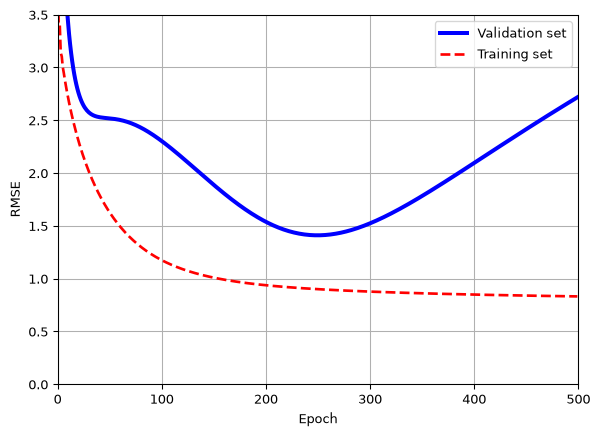

In [7]:
from copy import deepcopy
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import SGDRegressor

# Construct noisy quadratic data and reserve validation examples.
np.random.seed(42)
m = 100
X = 6 * np.random.rand(m, 1) - 3
y = 0.5 * X ** 2 + X + 2 + np.random.randn(m, 1)
X_train, y_train = X[: m // 2], y[: m // 2, 0]
X_valid, y_valid = X[m // 2 :], y[m // 2 :, 0]

preprocessing = make_pipeline(PolynomialFeatures(degree=90, include_bias=False),
                              StandardScaler())
X_train_prep = preprocessing.fit_transform(X_train)
X_valid_prep = preprocessing.transform(X_valid)
sgd_reg = SGDRegressor(penalty=None, eta0=0.002, random_state=42)
n_epochs = 500
best_valid_rmse = float('inf')
train_errors, val_errors = [], []  # extra code – it's for the figure below

for epoch in range(n_epochs):
    sgd_reg.partial_fit(X_train_prep, y_train)
    y_valid_predict = sgd_reg.predict(X_valid_prep)
    val_error = root_mean_squared_error(y_valid, y_valid_predict)
    if val_error < best_valid_rmse:
        best_valid_rmse = val_error
        best_model = deepcopy(sgd_reg)

    # extra code – we evaluate the train error and save it for the figure
    y_train_predict = sgd_reg.predict(X_train_prep)
    train_error = root_mean_squared_error(y_train, y_train_predict)
    val_errors.append(val_error)
    train_errors.append(train_error)

# extra code – this section generates and saves Figure 4–20
best_epoch = np.argmin(val_errors)
plt.plot(val_errors, "b-", linewidth=3, label="Validation set")
plt.plot(train_errors, "r--", linewidth=2, label="Training set")
plt.legend(loc="upper right")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.axis([0, n_epochs, 0, 3.5])
plt.grid()
plt.show()

**Attribution**: Géron (2022), <a
href="https://github.com/ageron/handson-ml3/blob/main/04_training_linear_models.ipynb"
class="external" data-icon="true">04_training_linear_models.ipynb</a>.

The earlier output and loss choices defined what the model should
predict. This figure introduces a second criterion for assessing
progress: performance on examples not used for the updates. The lowest
validation error identifies a more promising checkpoint than the final
epoch, despite the continuing improvement in training error.

A **checkpoint** is a saved copy of the model’s parameters at a
particular training step. The vertical axis uses **root mean squared
error (RMSE)**, the square root of MSE introduced in Lecture 4; lower
values indicate smaller prediction errors, in the target’s original
units.

The code intentionally runs all 500 epochs to show the complete curves
and stores the best model without marking it on the plot. It therefore
demonstrates checkpoint selection. An actual early-stopping procedure
also halts the updates when its stopping criterion is met. Validation
curves can fluctuate; a patience period avoids stopping at the first
small reversal. The curve motivates the stopping rule introduced next.

## Why regularize?

An appropriate loss and effective updates can still produce
**overfitting**.

- **Training loss** measures fit to the supplied examples.
- **Validation performance** helps identify choices that generalize.
- Stronger regularization can also cause underfitting.

The divergence between the training and validation curves explains why
reducing training loss is not the only goal. **Regularization influences
learning to favor solutions that generalize.** Stopping earlier controls
how long parameters are adjusted; penalties change the objective;
dropout changes training computations. Their usefulness and strength
should be assessed with validation data; the test set is reserved for
the final evaluation.

## Early stopping

How could the validation curve become a stopping rule?

Monitor a validation metric. Stop after a chosen number of epochs
without meaningful improvement, and recover the best parameters.

Geoffrey Hinton calls this the *“beautiful free lunch.”*

## Stop and restore the best parameters

For a compiled Keras model with prepared training and validation data:

``` python
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True)
    
model.fit(X_train, y_train, validation_data=(X_valid, y_valid),
          epochs=100, callbacks=[early_stopping])
```

Restoring the best weights is an explicit choice: Keras does not enable
it by default. Patience controls how many epochs without improvement are
allowed before stopping. A minimum improvement can also be set using
`min_delta`. Use validation data for this choice, not the test set. See
<a href="https://keras.io/api/callbacks/early_stopping/"
class="external" data-icon="true">Keras EarlyStopping</a>.

## Adding a penalty to the objective

Besides choosing when to stop, can we influence which solutions training
prefers?

$$
J_{\mathrm{reg}}(W,b)=J_{\mathrm{data}}(W,b)+\Omega(W).
$$

The data loss matches the prediction task. The penalty discourages
selected weight configurations.

The data term can be mean squared error, mean absolute error, BCE, or
categorical cross-entropy. For example, MAE averages $|\hat y_i-y_i|$
over regression examples. A penalty is added separately and is minimized
together with that data term. This presentation penalizes weights, not
biases, unless a different choice is explicitly stated.

## How could we measure weight size?

Would these two weight vectors receive the same penalty?

| Weights | Sum of absolute values | Sum of squares |
|:--------|-----------------------:|---------------:|
| $(4,0)$ |                      4 |             16 |
| $(2,2)$ |                      4 |              8 |

L1 uses $\|\mathbf w\|_1=\sum_j|w_j|$; the usual L2 penalty uses
$\|\mathbf w\|_2^2=\sum_j w_j^2$.

The two vectors have the same sum of absolute values, but distributing
the magnitude across both entries reduces the sum of squares. This
comparison explains how the penalties measure weight size differently;
it does not by itself prove that L1 will produce a sparse fitted model.
The data-loss term also influences the optimum.

The L1 norm is also called the Manhattan norm. The L2 or Euclidean norm
is the square root of the sum of squares; the usual L2 regularization
penalty uses its square, not the norm itself.

A **norm** assigns a non-negative length to a vector.

For $p\geq1$, the **$\ell_p$ norm** of a vector
$\mathbf{z} = [z_1, z_2, \ldots, z_n]$ is defined as:

$$
  \|\mathbf{z}\|_p = \left( \sum_{i=1}^{n} |z_i|^p \right)^{1/p}
$$

With larger $p$, the $\ell_p$ norm increasingly highlights larger $z_i$
values due to exponentiation.

A **norm** is nonnegative and is zero only for the zero vector. Scaling
a vector by a scalar $c$ scales its norm by $|c|$:
$\|c\mathbf z\|=|c|\,\|\mathbf z\|$. The **triangle inequality**,
$\|\mathbf u+\mathbf v\|\leq\|\mathbf u\|+\|\mathbf v\|$, says that the
length of a sum is at most the sum of the lengths.

## $\ell_1$ and $\ell_2$ regularization

Let $\mathbf w$ collect all weight entries. The nonnegative coefficients
$\lambda_1$ and $\lambda_2$ control the penalties; zero disables the
corresponding term.

$$
J_{\mathrm{reg}}=J_{\mathrm{data}}(W,b)
+\lambda_1\|\mathbf w\|_1
+\frac{\lambda_2}{2}\|\mathbf w\|_2^2.
$$

The L1 term sums absolute weight values. The usual L2 penalty sums
squared weight values; it uses the squared Euclidean or Frobenius norm,
rather than the unsquared norm. The factor one-half is a convention that
makes its derivative $\lambda_2 W$, matching `SimpleMLP` later in this
presentation. Coefficient conventions differ across libraries.

## Shrinkage and sparsity

- **$\ell_1$ Regularization**:
  - Encourages **sparsity**; suitable solvers can set coefficients
    exactly to zero.
  - Can support **feature selection**, particularly in linear models.
- **$\ell_2$ Regularization**:
  - Promotes **small, distributed weights** for stability.
  - Shrinks weights collectively and usually retains a dense solution.

An advanced example: [Regularization with correlated features
](kong_and_yu-2018.qmd).

A **sparse coefficient vector** has many exact zeros; a **dense** vector
has few or none. **Feature selection** means retaining a subset of the
original input features. In a linear model, a zero coefficient removes
that feature’s term from the prediction. Whether the selected subset
improves prediction must be evaluated separately. **Correlated
features** vary together; their overlapping information can affect which
coefficients are selected or how weight is distributed between them.

## Which coefficients actually disappear?

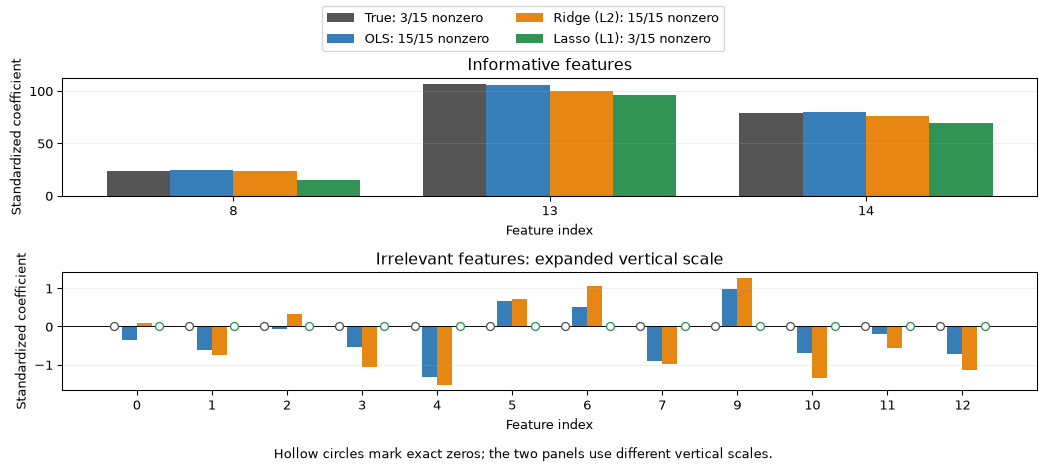

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler

X, y, true_coef = make_regression(n_samples=200, n_features=15, n_informative=3,
                                 noise=10.0, coef=True, random_state=42)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Express the known coefficients in the same coordinates as the fitted models.
true_coef_scaled = true_coef * scaler.scale_
coefficient_models = {
    'OLS': LinearRegression().fit(X_scaled, y),
    'Ridge (L2)': Ridge(alpha=10.0).fit(X_scaled, y),
    'Lasso (L1)': Lasso(alpha=10.0).fit(X_scaled, y)
}

series = [('True', true_coef_scaled)] + [
    (name, fitted.coef_) for name, fitted in coefficient_models.items()
]
colors = ['#555555', '#377eb8', '#e68613', '#319354']
groups = [
    (true_coef != 0, 'Informative features'),
    (true_coef == 0, 'Irrelevant features: expanded vertical scale')
]
fig, axes = plt.subplots(2, 1, figsize=(11, 4.8))
for ax, (mask, title) in zip(axes, groups):
    feature_indices = np.flatnonzero(mask)
    positions = np.arange(len(feature_indices))
    for offset, ((name, values), color) in enumerate(zip(series, colors)):
        x_positions = positions + (offset-1.5)*0.2
        nonzero = np.count_nonzero(values)
        ax.bar(x_positions, values[mask], width=0.2, color=color,
               label=f'{name}: {nonzero}/15 nonzero')
        zeros = values[mask] == 0
        ax.scatter(x_positions[zeros], values[mask][zeros], s=35,
                   facecolors='white', edgecolors=color, zorder=4)
    ax.set(xticks=positions, xticklabels=feature_indices, xlabel='Feature index',
           ylabel='Standardized coefficient', title=title)
    ax.axhline(0, color='black', linewidth=0.7)
    ax.grid(axis='y', alpha=0.2)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2)
fig.text(0.5, 0.01, 'Hollow circles mark exact zeros; the two panels use different vertical scales.',
         ha='center')
fig.tight_layout(rect=(0, 0.035, 1, 0.91))
plt.show()

[Regularization: shrinkage and sparsity ](regularization.qmd).

This linear-regression example isolates the penalty’s effect. Fifteen
predictors are generated, but only three have nonzero true coefficients.
The informative and irrelevant features use different vertical scales so
that small nonzero estimates remain visible. Hollow circles identify
exact zeros. With these fixed settings, OLS and Ridge retain fifteen
nonzero coefficients; Lasso retains three, giving 80% exact-zero
sparsity and identifying the informative predictors in this dataset.

**Ordinary least squares (OLS)** fits a linear model by minimizing the
**residual sum of squares (RSS)**. A residual is an observed target
minus its prediction; RSS sums the squared residuals over examples. This
is the least-squares objective from Lecture 4 under its statistical
name. **Ridge** adds a squared L2 coefficient penalty, while **Lasso**
adds an L1 coefficient penalty. See the
<a href="https://scikit-learn.org/stable/modules/linear_model.html"
class="external" data-icon="true">scikit-learn linear-model
definitions</a>.

OLS is the unregularized baseline. The equal numeric alpha values do not
imply equal penalty strengths. Scikit-learn Ridge minimizes RSS plus
alpha times the squared L2 norm, whereas Lasso divides RSS by $2N$
before adding its L1 penalty. The settings were chosen for a qualitative
comparison, not a matched-strength benchmark.

The models use standardized features: each is centered using its
training mean and divided by its training standard deviation. The true
coefficients are converted to the same coordinates. Changing feature
units changes the coefficient needed to preserve a prediction, and
therefore its penalty; standardization makes the scale assumption
explicit. The generated features already have similar scales, so it
makes only a small numerical difference here. For held-out evaluation,
fit the scaler only on training data. The companion notebook explains
the coefficient conversion and prints the complete counts.

## Adding L2 in Keras

``` python
import keras

l2 = 0.001
regularizer = keras.regularizers.L2(l2 / 2)
dense = keras.layers.Dense(50, kernel_regularizer=regularizer)
```

For a Dense layer, the **kernel** is its weight matrix. Apply the
penalty to each layer whose weights should be penalized.

Keras `L2(c)` adds $c\sum w^2$, so its derivative is $2cW$. Using
`c=l2/2` matches the $\lambda/2$ convention in this presentation and
`SimpleMLP`. A numeric penalty coefficient is meaningful only together
with its library’s definition. `kernel_regularizer` does not penalize
the bias; that is a separate option. See
<a href="https://keras.io/api/layers/regularizers/" class="external"
data-icon="true">Keras regularizers</a>.

## What if some activations were unavailable?

Could temporarily removing some hidden activations help a model
generalize?

- **Dropout** randomly sets some activations to zero during training.
- **Objective:** reduce overfitting by discouraging reliance on
  particular units always being available.

Hinton et al. (2012)

Suppose a prediction depends heavily on one hidden unit. When dropout
sets that unit’s activation to zero for a training example, its
contribution is unavailable. The remaining units must provide the
information used for that prediction. Repeating this with different
activations removed encourages the model to make useful predictions
without depending too heavily on particular combinations of units
(Hinton et al. 2012).

The aim is better performance on new examples. Training may become
harder and training loss may increase; validation performance determines
whether dropout helps generalization. Excessive dropout can cause
underfitting.

Weight penalties change the objective by adding a term that depends on
the weights. Dropout changes the training computation. The same model
parameters are shared across these computations, and different
activations are randomly selected for removal as training proceeds. The
units and their weights remain part of the model; their activation
values are temporarily changed.

## Why scale the retained activations?

An activation equals 4 before dropout and is dropped half the time. What
is its average value afterward?

| Outcome                  | Without scaling | With scaling |
|:-------------------------|----------------:|-------------:|
| Dropped (half the time)  |               0 |            0 |
| Retained (half the time) |               4 |            8 |
| **Average**              |           **2** |        **4** |

For dropout rate $p$, divide each retained activation by $1-p$.

The **dropout rate** $p$ is the probability of setting an activation to
zero during training, with $0\leq p<1$. The activation is retained with
probability $1-p$. The choices in the table are equally likely because
$p=0.5$.

Without scaling, the average is $(0+4)/2=2$. Dividing each retained
activation by $1-p=0.5$ doubles it, giving an average of $(0+8)/2=4$.
This compensates for the activations that were dropped. More generally,
an original activation $a$ becomes zero when dropped and $a/(1-p)$ when
retained.

The average describes many repetitions with the same original
activation; a single computation produces either 0 or 8 in this example.
Scaling keeps the average activation magnitude comparable to ordinary
use, while individual computations still have missing activations. That
variation provides the regularizing effect. It does not guarantee that
the network’s final prediction is preserved on average, because later
layers can be nonlinear.

With the usual Keras settings, the random choices are made separately
for each example and activation. A unit can therefore be dropped on some
examples and retained on others in the same batch. For an example on
which an activation is dropped, no gradient passes through that
activation; other examples can still contribute to updates of the unit’s
parameters.

## Training and inference

Should activations still be dropped when the trained model makes
predictions?

| Mode      | Drop activations? | Rescale retained activations? |
|:----------|:------------------|:------------------------------|
| Training  | Yes, at rate $p$  | Yes, by $1/(1-p)$             |
| Inference | No                | No                            |

During ordinary inference, all units are available and dropout leaves
their activations unchanged. Because the retained activations were
scaled during training, no additional dropout scaling is needed at
inference.

Keras handles this distinction automatically: dropout is active for
training inside `model.fit`, and inactive for validation,
`model.evaluate`, and `model.predict`. Validation therefore measures the
model under its ordinary prediction conditions. See
<a href="https://keras.io/api/layers/regularization_layers/dropout/"
class="external" data-icon="true">Keras Dropout</a>.

## Dropout in the Fashion-MNIST model

``` python
import keras
from keras.models import Sequential
from keras.layers import InputLayer, Dropout, Flatten, Dense

model = keras.Sequential([
    InputLayer(shape=[28, 28]),
    Flatten(),
    Dropout(rate=0.2),
    Dense(300, activation="relu"),
    Dropout(rate=0.2),
    Dense(100, activation="relu"),
    Dropout(rate=0.2),
    Dense(10, activation="softmax")
])
```

Adding `Dropout` layers to the Fashion-MNIST model from Lecture 11. A
rate of 0.2 drops each activation with probability 20% during training.

Each `Dropout` layer acts on the activations supplied by the preceding
layer. After `Flatten`, these are the input pixel values; after a
`Dense` layer, they are hidden-unit activations. A `Dropout` layer adds
no trainable weights. Backpropagation still computes the gradients for
the surrounding Dense layers, and the optimizer updates their parameters
as before.

The rate is a probability for each activation; exactly 20% need not be
dropped on every example. With `rate=0.2`, a retained activation is
divided by 0.8, or multiplied by 1.25, during training. The rate can
differ by layer.

The example illustrates where to insert dropout in a familiar
architecture. Whether it improves predictions should be checked by
comparing validation performance with an otherwise comparable model
without dropout. Choose the rates using validation data; too much
dropout can make useful patterns harder to learn.

# Further learning and retention

## Inference and further learning

The model works well. Can it keep learning from new examples without
losing earlier capabilities?

- **Inference:** compute predictions using the current parameters.
- **Further learning:** update parameters using an explicit training
  process.
- Evaluate updates on **earlier capabilities** as well as new data.

A model does not ordinarily change its weights merely by receiving
another prediction request. Feedback, an objective, and an update
procedure are needed for learning. A training pipeline can periodically
produce a new model version, or it can update continuously.

**Online learning** updates a model incrementally as new observations
arrive, rather than relying only on a fixed training dataset and a
separate retraining run. **Fine-tuning** means further training a
previously trained model. **Continual learning** studies learning from
successive data or tasks while retaining earlier capabilities. These
terms describe learning processes; ordinary inference computes outputs
without performing such updates.

Production neural networks can learn online; real-time recommendation
systems such as
<a href="https://arxiv.org/abs/2209.07663" class="external"
data-icon="true">Monolith</a> provide examples. The distinction is
between inference and a deliberate update process, not a universal
prohibition on online training. See <a
href="https://developers.google.com/machine-learning/crash-course/production-ml-systems/static-vs-dynamic-training"
class="external" data-icon="true">Google’s static/dynamic training
discussion</a>.

## Will learning B preserve skill A?

| Phase | Training data    | Evaluate afterwards |
|:------|:-----------------|:--------------------|
| A     | MNIST digits 0–4 | Both groups         |
| B     | MNIST digits 5–9 | Both groups         |

Keep the same ten output classes and the original labels throughout.

After phase B, what do you predict will happen to accuracy on digits
0–4?

The model first trains on digits 0–4 and then continues training on
digits 5–9. Its output dimension and the meaning of every class label
stay fixed. The second phase therefore tests whether learning new
classes preserves earlier predictions without additional old examples.
This differs from ordinary inference, which leaves the parameters
unchanged.

**MNIST** contains 28-by-28 grayscale images of handwritten digits 0–9.
It differs from Fashion-MNIST, the clothing-image dataset used earlier.
A **class-incremental** setup introduces classes in successive phases
and evaluates the model’s ability to recognize all classes seen so far;
after phase B here, that means all ten digits.

This is a class-incremental setup: all ten classes are available for
every prediction. Restricting predictions to the task’s known class
group would answer a different, easier question. See
<a href="https://arxiv.org/abs/1904.07734" class="external"
data-icon="true">van de Ven and Tolias (2019)</a>.

## What happened to the earlier classes?

Test accuracy in the recorded MNIST run:

| Checkpoint   | Digits 0–4 (A) | Digits 5–9 (B) |
|:-------------|---------------:|---------------:|
| After A      |          97.0% |           0.0% |
| After B only |           2.3% |          93.8% |

Which examples were absent from phase B? How could we put some of that
information back?

**Catastrophic forgetting:** further training can sharply reduce
performance on earlier tasks.

These are stage-end test accuracies from the companion’s recorded run,
not the validation accuracies plotted on the following slide. They use
all ten output classes at every evaluation. Exact values can vary with
backend and hardware, but this run illustrates a pronounced loss of
earlier class accuracy alongside successful learning of the newer
classes.

The second training objective contains no examples requiring the earlier
predictions to remain correct. Its updates can interfere with shared
representations and favor recent classes. The original test images and
their labels do not change. A decline is not evidence that every useful
old representation has been erased.

The missing old examples suggest a direct intervention: retain a small
memory and mix some earlier examples into later updates. That proposal
is tested next, using the same initial learned parameters and update
count for both phase-B branches.

## Could a small memory help?

What would change if some phase-B updates also included earlier
examples?

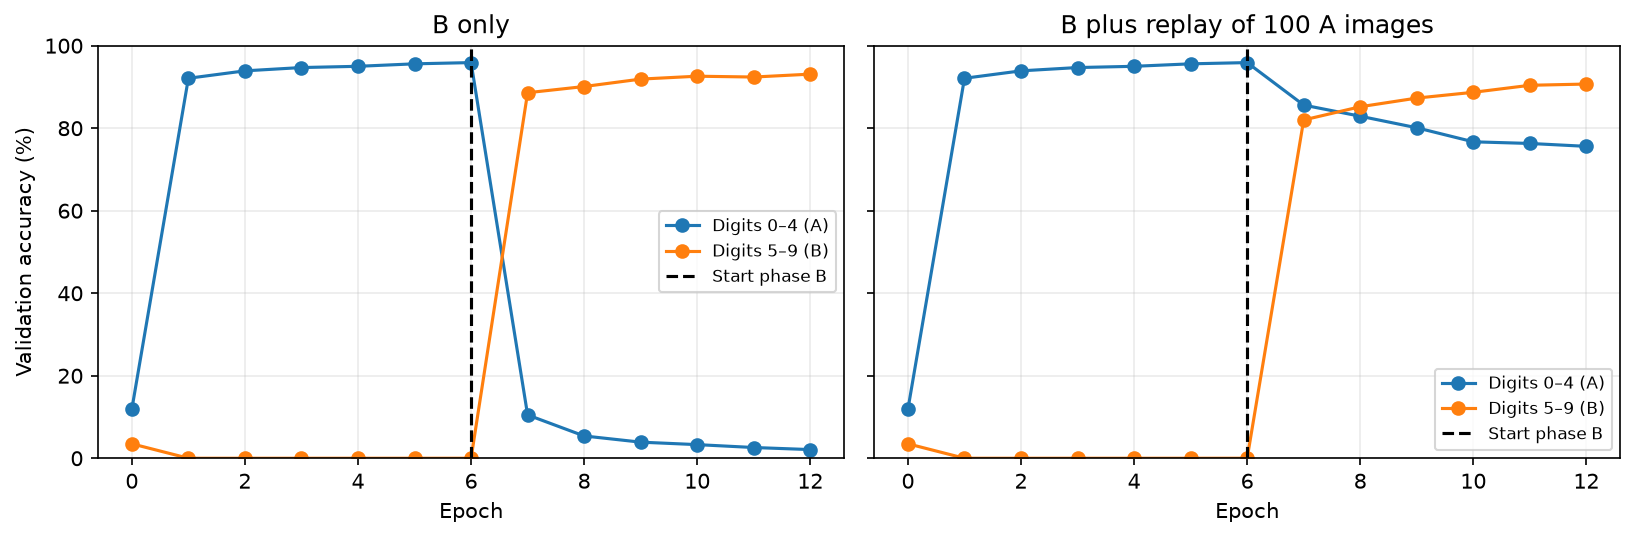

[Catastrophic forgetting on MNIST ](catastrophic_forgetting.qmd):
reproduce the experiment and inspect stage-end test results.

The panels share the same phase-A training history and start phase B
from identical learned parameters. Both phase-B branches have the same
batch size and number of parameter updates. The second branch uses half
of each batch for replay from a balanced memory of 100 old training
images, changing the data mixture within that budget.

A **balanced memory** stores equal numbers from each earlier class:
here, 20 images from each of the five A classes. **Retention** is
continued performance on earlier data after subsequent training.

This use of stored earlier examples is called replay. In this run it
substantially improves retention while the model still learns the newer
classes; it does not preserve the earlier accuracy perfectly.

The figure uses validation accuracy to follow both capabilities. The
companion records predeclared stage-end measurements on MNIST’s official
test set and reports the drop in A accuracy separately. New-task
performance alone would hide the retention problem.

Replay reintroduces an objective on earlier data. Ordinary zero-centered
L2 discourages large weights; it does not explicitly preserve previous
predictions. As further reading,
<a href="https://arxiv.org/abs/1612.00796" class="external"
data-icon="true">elastic weight consolidation (EWC)</a> penalizes
changes away from previously learned parameter values, with stronger
penalties for parameters estimated to be important to earlier tasks.
Catastrophic forgetting matters during periodic batch fine-tuning as
well as online updates.

# Epilogue

## Summary

- **Optimization:** a correct local gradient does not guarantee
  successful training.
- **Gradient propagation:** activation choice, initialization, clipping,
  and update size address different difficulties.
- **Outputs and losses:** choose the output representation and objective
  together; distinguish logits, probabilities, and class labels.
- **Generalization:** L1/L2, dropout, and early stopping can help;
  evaluate their strength with validation data.
- **Retention:** further training can cause forgetting; evaluate old
  capabilities and consider mechanisms such as replay.
- **Implementation:** `SimpleMLP` preserves the backpropagation
  structure while adding training choices.

## Next lecture

For images, could an architecture use spatial structure instead of
treating every input connection alike?

- Convolutional neural networks address this architectural question.

## References

Géron, Aurélien. 2022. *Hands-on Machine Learning with Scikit-Learn,
Keras, and TensorFlow*. 3rd ed. O’Reilly Media, Inc.

Glorot, Xavier, and Yoshua Bengio. 2010. “Understanding the Difficulty
of Training Deep Feedforward Neural Networks.” In *Proceedings of the
Thirteenth International Conference on Artificial Intelligence and
Statistics*, edited by Yee Whye Teh and Mike Titterington, vol. 9.
Proceedings of Machine Learning Research. PMLR.
<https://proceedings.mlr.press/v9/glorot10a.html>.

Hinton, Geoffrey E., Nitish Srivastava, Alex Krizhevsky, Ilya Sutskever,
and Ruslan Salakhutdinov. 2012. “Improving Neural Networks by Preventing
Co-Adaptation of Feature Detectors.” *CoRR* abs/1207.0580.
<http://arxiv.org/abs/1207.0580>.

Krizhevsky, Alex, Ilya Sutskever, and Geoffrey E Hinton. 2012. “ImageNet
Classification with Deep Convolutional Neural Networks.” In *Advances in
Neural Information Processing Systems*, edited by F. Pereira, C. J.
Burges, L. Bottou, and K. Q. Weinberger, vol. 25. Curran Associates,
Inc.
<https://proceedings.neurips.cc/paper_files/paper/2012/file/c399862d3b9d6b76c8436e924a68c45b-Paper.pdf>.

LeCun, Yann, Yoshua Bengio, and Geoffrey Hinton. 2015. “Deep Learning.”
*Nature* 521 (7553): 436–44. <https://doi.org/10.1038/nature14539>.

Rumelhart, David E., Geoffrey E. Hinton, and Ronald J. Williams. 1986.
“<span class="nocase">Learning representations by back-propagating
errors</span>.” *Nature* 323 (6088): 533–36.
<https://doi.org/10.1038/323533a0>.

Russell, Stuart, and Peter Norvig. 2020. *Artificial Intelligence: A
Modern Approach*. 4th ed. Pearson. <http://aima.cs.berkeley.edu/>.

# Appendix: Extending the implementation

## From SimplerMLP to SimpleMLP

Which choices require code changes, and where do they enter the
computation?

| Component | `SimplerMLP` (Lecture 13) | `SimpleMLP` |
|:-----------------------|:-----------------------|:-----------------------|
| Hidden activation | Sigmoid | Sigmoid or ReLU |
| Initialization | Glorot | He for ReLU; Glorot for sigmoid |
| Output | Sigmoid probability | Sigmoid probability |
| Learning rate | Constant | Constant or exponential decay |
| Loss | Mean BCE | Mean BCE plus optional L2 |
| Dropout | None | Optional; one rate for all hidden layers |
| Example order | Shuffle every epoch | Optional shuffling (default: on) |
| Forward caches | Activations and preactivations | Also scaled dropout masks |
| Prediction and training API | Same methods | Same methods |

The new class extends the previous implementation while retaining its
computational structure. Both are binary classifiers with one sigmoid
output. Changing the hidden activation requires a matching local
derivative and suitable initialization, but the chain rule and backward
loop remain the same.

Each addition answers a problem encountered earlier: activation helpers
select local slopes, initialization controls the starting weight scale,
L2 adds a weight penalty, dropout changes the training computation, and
a schedule changes update size over epochs. The activation and
preactivation caches, parameter orientation, and gradient-collection
procedure remain aligned with Lecture 13. Dropout adds a cache of scaled
masks and one corresponding factor in the backward pass.

This class implements a selected subset of the lecture’s choices. It
retains binary BCE and does not implement multiclass softmax, early
stopping, or gradient clipping. The Keras examples and companions
illustrate those broader tools. Separating these scopes keeps the NumPy
implementation readable while preserving the connection between concepts
and code.

Setting `hidden_activation="sigmoid"`, `l2=0.0`, `lr_decay=None`, and
`dropout_rate=0.0` recovers the `SimplerMLP` computation. With the same
seed and the default `shuffle=True`, the two classes initialize and
shuffle identically. `SimpleMLP` adds a `shuffle` option to `train`:
setting `shuffle=False` preserves the supplied example order across
epochs. This is useful when training depends on that order, as discussed
in Lecture 13; it does not by itself make this feedforward classifier a
sequence model. The complete definition and focused excerpts follow
below. They remain available for independent notebook execution.

## SimpleMLP

In [9]:
import numpy as np

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def sigmoid_prime(z):
    a = sigmoid(z)
    return a * (1.0 - a)

def bce_loss(y_true, y_prob, eps=1e-9):
    """Binary cross-entropy averaged over examples."""
    p = np.clip(y_prob, eps, 1 - eps)
    return -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

def xavier_init(rng, fan_in, fan_out):
    std = np.sqrt(2.0 / (fan_in + fan_out))
    return rng.normal(0.0, std, size=(fan_in, fan_out))

def relu(z):
    return np.maximum(0.0, z)

def relu_prime(z):
    return (z > 0).astype(float)

def he_init(rng, fan_in, fan_out):
    std = np.sqrt(2.0 / fan_in)
    return rng.normal(0.0, std, size=(fan_in, fan_out))

class SimpleMLP:
    """Binary MLP with hidden activation choice, L2, dropout, and LR decay."""

    def __init__(self, layer_sizes, lr=0.1, seed=None, l2=0.0,
                 hidden_activation="relu", lr_decay=None, dropout_rate=0.0):
        self.sizes = list(layer_sizes)
        self.lr = float(lr)
        self.base_lr = float(lr)
        self.l2 = float(l2)
        self.hidden_activation = hidden_activation
        self.lr_decay = lr_decay
        self.dropout_rate = float(dropout_rate)
        self.rng = np.random.default_rng(seed)

        self.W = []
        L = len(self.sizes) - 1
        for l, (din, dout) in enumerate(zip(self.sizes[:-1], self.sizes[1:]), start=1):
            if l < L and self.hidden_activation == "relu":
                Wk = he_init(self.rng, din, dout)
            else:
                Wk = xavier_init(self.rng, din, dout)
            self.W.append(Wk)
        self.b = [np.zeros(dout) for dout in self.sizes[1:]]

    def _act(self, z, last=False):
        if last:
            return sigmoid(z)
        return relu(z) if self.hidden_activation == "relu" else sigmoid(z)

    def _act_prime(self, z, last=False):
        if last:
            return sigmoid_prime(z)
        return relu_prime(z) if self.hidden_activation == "relu" else sigmoid_prime(z)

    def forward(self, X):
        a = X
        L = len(self.W)
        for l, (W, b) in enumerate(zip(self.W, self.b), start=1):
            a = self._act(a @ W + b, last=(l == L))
        return a.ravel()

    def predict_proba(self, X):
        return self.forward(X)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    def loss(self, X, y):
        """Report mean BCE plus L2 with dropout disabled."""
        p = self.predict_proba(X)
        base = bce_loss(y, p)
        if self.l2 > 0:
            base += 0.5 * self.l2 * sum((W ** 2).sum() for W in self.W)
        return base

    def _forward_full(self, X):
        a = X
        activations = [a]
        zs = []
        dropout_masks = []
        L = len(self.W)
        for l, (W, b) in enumerate(zip(self.W, self.b), start=1):
            z = a @ W + b
            a = self._act(z, last=(l == L))

            # Identity mask for the output layer and when dropout is disabled.
            mask = np.ones_like(a)
            if l < L and self.dropout_rate > 0:
                keep_prob = 1.0 - self.dropout_rate
                mask = (self.rng.random(a.shape) >= self.dropout_rate) / keep_prob
                a = a * mask

            zs.append(z)
            activations.append(a)
            dropout_masks.append(mask)
        return activations, zs, dropout_masks

    def train(self, X, y, epochs=30, batch_size=None, verbose=True, shuffle=True):
        """X: (N, d), y: (N,); batch_size=None uses the full dataset."""
        N = X.shape[0]
        idx = np.arange(N)
        B = N if batch_size is None else int(batch_size)

        for ep in range(1, epochs + 1):
            if shuffle:
                self.rng.shuffle(idx)
            if self.lr_decay is not None:
                self.lr = self.base_lr * self.lr_decay ** (ep - 1)

            base_loss = self.loss(X, y)

            for start in range(0, N, B):
                sl = idx[start:start + B]
                Xb = X[sl]
                yb = y[sl].reshape(-1, 1)
                Bsz = Xb.shape[0]

                activations, zs, dropout_masks = self._forward_full(Xb)
                A_L = activations[-1]

                # Each row is a single example's preactivation sensitivity.
                delta = A_L - yb
                grads_W = [None] * len(self.W)
                grads_b = [None] * len(self.b)

                # Average parameter gradients over examples exactly once.
                grads_W[-1] = activations[-2].T @ delta / Bsz
                grads_b[-1] = delta.mean(axis=0)

                for k in range(len(self.W) - 2, -1, -1):
                    z = zs[k]
                    d_act = self._act_prime(z, last=False)
                    delta = delta @ self.W[k + 1].T
                    delta = delta * dropout_masks[k]
                    delta = delta * d_act
                    grads_W[k] = activations[k].T @ delta / Bsz
                    grads_b[k] = delta.mean(axis=0)

                if self.l2 > 0:
                    for k in range(len(self.W)):
                        grads_W[k] += self.l2 * self.W[k]

                # All gradients use the weights from the same forward pass.
                for k in range(len(self.W)):
                    self.W[k] -= self.lr * grads_W[k]
                    self.b[k] -= self.lr * grads_b[k]

            new_loss = self.loss(X, y)
            if verbose:
                print(f"Epoch {ep:3d} | loss {base_loss:.5f} -> {new_loss:.5f} | lr={self.lr:.4f}")

## Choosing hidden activations

If the forward activation changes, which local derivative must the
backward pass use?

``` python
    def _act(self, z, last=False):
        if last:
            return sigmoid(z)
        return relu(z) if self.hidden_activation == "relu" else sigmoid(z)

    def _act_prime(self, z, last=False):
        if last:
            return sigmoid_prime(z)
        return relu_prime(z) if self.hidden_activation == "relu" else sigmoid_prime(z)
```

The output remains sigmoid for binary classification. ReLU is an option
only for hidden units. Lecture 13 called `sigmoid` and `sigmoid_prime`
directly. Here the helpers `_act` and `_act_prime` select the activation
and its derivative, and the flag `last` identifies the output layer. The
forward and cached-forward methods now call `_act`; the backward loop
calls `_act_prime`. Its multiplication by `W_next.T` and its averaging
over examples are unchanged.

## L2 in the objective and gradient

$$
J_{\mathrm{reg}}=J_{\mathrm{BCE}}+
\frac{\lambda}{2}\sum_{l=1}^{L}\|W^{(l)}\|_F^2.
$$

``` python
base += 0.5 * self.l2 * sum((W ** 2).sum() for W in self.W)

# After computing the mean data-loss gradients:
grads_W[k] += self.l2 * self.W[k]
```

The coefficient `l2` is $\lambda$. The data loss is averaged over
examples; the penalty is added separately, with no additional division
by dataset or mini-batch size. Consequently, its derivative is
$\lambda W$ in every batch. This keeps the L2 term in the reported loss
consistent with its contribution to each update. Biases are not
penalized in this implementation.

The Frobenius norm squared is simply the sum of squared entries of a
weight matrix. This implements the squared L2 penalty introduced
earlier. L2 discourages large weights; it does not change the local
activation derivatives or directly repair gradient propagation.

## Dropout in the forward and backward passes

What extra local derivative does dropout introduce?

During the training forward pass, for a hidden layer:

``` python
keep_prob = 1.0 - self.dropout_rate
mask = (self.rng.random(a.shape) >= self.dropout_rate) / keep_prob
a = a * mask
```

During the backward pass, reuse the cached scaled mask:

``` python
delta = delta * dropout_masks[k]
```

Enable with `dropout_rate=0.2`; the default of zero disables dropout.

`SimpleMLP` uses one rate for **all hidden layers**. Keras lets you
place `Dropout` layers individually and choose their rates separately.

For dropout rate $0\leq p<1$, each mask entry is zero with probability
$p$ and $1/(1-p)$ otherwise. Its shape matches the batch’s activation
array, so the choices are made separately for each example and hidden
unit. The mask is sampled once in the training forward pass and retained
for its backward pass. A new mask is sampled on the next training
forward pass.

For a fixed sampled mask, $\widetilde a=ma$ has local derivative $m$
with respect to $a$. The backward pass therefore multiplies by the same
scaled mask. A dropped activation blocks that path’s gradient; a
retained activation also passes the scaling factor. The activation
derivative is evaluated using the cached preactivation `zs[k]`, before
dropout. In particular, the sigmoid derivative must not be calculated
from an activation that has already been masked and scaled.

The `activations` cache stores the values actually passed to the next
layer, including dropout. Parameter gradients use these same values. The
output is not dropped, so its sigmoid/BCE error signal remains
`A_L - yb`.

This implementation applies the same rate to every hidden layer. It does
not apply dropout to the raw inputs or output. In Keras, dropout is
configured through separate layers placed at selected positions, with
independently chosen rates; see
<a href="https://keras.io/api/layers/regularization_layers/dropout/"
class="external" data-icon="true">Keras Dropout</a>.

Only `_forward_full`, used for training, applies dropout. The public
`forward`, prediction methods, and reported `loss` use the complete
network with dropout disabled. Thus, the printed loss is a deterministic
evaluation at the current parameters, while each training batch’s
data-loss gradients come from its sampled dropout computation. The
constructor seed controls initialization, shuffling, and mask sampling.
With `dropout_rate=0.0`, no mask random numbers are drawn, preserving
the earlier implementation’s seeded behavior.

## Same API, extended model

In [10]:
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

X, y = make_circles(n_samples=200, factor=0.5, noise=0.08, random_state=1)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = SimpleMLP([2, 4, 4, 1], lr=0.3, seed=42,
                  hidden_activation="relu", l2=0.001, lr_decay=0.995)
model.train(X_train, y_train, epochs=500, batch_size=32, verbose=False)

print("Train acc:", accuracy_score(y_train, model.predict(X_train)))
print(" Test acc:", accuracy_score(y_test, model.predict(X_test)))

Train acc: 1.0
 Test acc: 1.0

This uses the same data, split, preprocessing, and architecture as the
`SimplerMLP` example. It demonstrates the activation, penalty, and
learning-rate options; dropout remains disabled at its default rate of
zero. Because the activation, training duration, penalty, and schedule
differ, these two runs are illustrative workflows rather than a
controlled claim that one setting is universally better. The constructor
seed controls weights, shuffling, and dropout masks when enabled. All
gradients are still collected before updates.

Once a model has been trained and evaluated, a different question
arises: what happens to its existing capabilities if its parameters are
adjusted using new data?

## Computing softmax safely

Subtracting the largest logit preserves the probabilities and avoids
exponentiating large positive values.

In [11]:
import numpy as np

logits = np.array([1000.0, 1001.0, 999.0])
exp_scores = np.exp(logits-logits.max())
probabilities = exp_scores/exp_scores.sum()
print('Probabilities:', probabilities.round(4))
print('Sum:', probabilities.sum())

Probabilities: [0.2447 0.6652 0.09  ]
Sum: 0.9999999999999999

------------------------------------------------------------------------

Marcel **Turcotte**

<Marcel.Turcotte@uOttawa.ca>

School of Electrical Engineering and **Computer Science** (EE**CS**)

University of Ottawa